# Seminar 7 · Build a DDPM on MNIST
**MIPT / ШАД (YSDA) · 5 November 2026**

[Theory](seminar7.ipynb) · [Open in Colab](https://colab.research.google.com/github/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/seminars/seminar7/seminar7_ddpm_mnist.ipynb)

Build the noise schedule, a small time-conditioned U-Net, the training objective, and two samplers in PyTorch. Train **one model**, then compare DDPM and DDIM using **the same EMA weights and initial noise**. No diffusion library or pretrained generator is required.

In Colab select **Runtime → Change runtime type → GPU**, then run the cells in order. Training can take several minutes or longer depending on the GPU; use the measured update time to estimate the remaining budget. `TRAIN_STEPS=5000` is a teaching default, not a quality guarantee. CPU is suitable for a short smoke run; use a GPU for the full exercise.

This notebook includes complete reference implementations. Before reading each implementation, answer its question or try writing the indicated expression yourself. Checkpoints are saved inside the runtime; download them before the Colab runtime disconnects.

**Saved local demonstration:** 1,500 optimizer updates, batch size 64, Apple MPS, 32 generated samples, two timing repeats. The cells retain Colab defaults (5,000 updates, batch size 128, 64 samples, three repeats). Saved figures are an early-training demonstration; run the notebook on Colab for the default experiment. Local measurements are not Colab GPU benchmarks.

**Extra experiment (Section 10):** condition on the requested digit. Add a learned label embedding, train with image–label pairs, and compare DDPM/DDIM with the same labels and initial noise.

**Classifier-free guidance (Section 11):** jointly train with label dropout; compare guidance scales 0/1/2/4/8 using fixed starting noise, saved image grids and class-agreement/diversity diagnostics.

## 1. Setup
Use the PyTorch and torchvision versions installed in Colab. The only additional packages used below are NumPy, Matplotlib, pandas, and tqdm, also normally preinstalled. No repository clone or helper module is needed.

In [ ]:
import copy, math, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import MNIST
from torchvision.utils import make_grid
from tqdm.auto import trange

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
T = 200
TRAIN_STEPS = 5000
BATCH_SIZE = 128
LEARNING_RATE = 2e-4
CHECKPOINT = Path("mnist_ddpm_checkpoint.pt")
DATA_ROOT = Path("data")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

def synchronize():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

print(f"Device: {device}; torch: {torch.__version__}; seed: {SEED}")

Device: mps; torch: 2.6.0; seed: 42


## 2. Data in [-1, 1]
Sections 1–9 ignore digit labels: this is **unconditional** generation. Section 10 reuses the labels for class-conditional generation. The training split supplies images; 256 test images are reserved for a fixed-noise validation diagnostic. Validation MSE measures noise prediction, not sample quality.

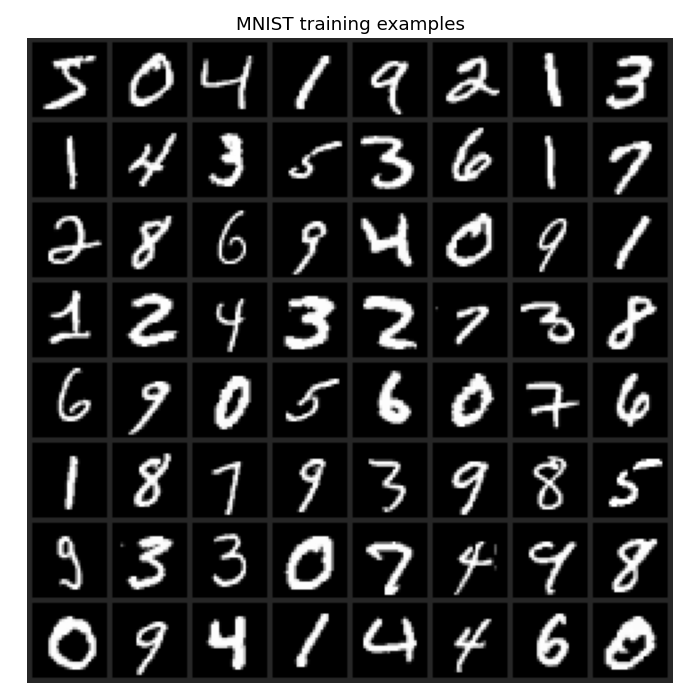

In [ ]:
train_set = MNIST(DATA_ROOT, train=True, download=True)
test_set = MNIST(DATA_ROOT, train=False, download=True)
# Keep compact uint8 tensors on the CPU; transfer only each selected batch.
train_images = train_set.data[:, None]
validation_images = test_set.data[:256, None].float().to(device) / 127.5 - 1

def show_grid(x, title, nrow=8, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(7, 7))
    grid = make_grid((x.detach().cpu().clamp(-1, 1) + 1) / 2,
                     nrow=nrow, padding=2, pad_value=0.15)
    ax.imshow(grid.permute(1, 2, 0)); ax.axis("off"); ax.set_title(title)
    return ax

show_grid(train_images[:64].float() / 127.5 - 1, "MNIST training examples")
plt.tight_layout(); plt.show()

## 3. Forward diffusion
**Try first:** implement $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$ with batch-specific $t$.

Code uses zero-based indices: index `0` is the **first noisy step**, index `T-1` is the last. The clean endpoint is represented by index `-1` in sampling and has $\bar\alpha=1$.

We use a cosine cumulative schedule so that a 200-step teaching model still reaches nearly pure noise. Each one-step beta is capped below one. This choice changes the schedule, not the DDPM/DDIM comparison.

Source: [Nichol & Dhariwal, Improved DDPM (2021)](https://arxiv.org/abs/2102.09672).

In [ ]:
def cosine_schedule(steps, offset=0.008):
    u = torch.linspace(0, steps, steps + 1, dtype=torch.float64)
    cumulative = torch.cos(((u / steps + offset) / (1 + offset)) * math.pi / 2).square()
    cumulative = cumulative / cumulative[0]
    betas = (1 - cumulative[1:] / cumulative[:-1]).clamp(1e-5, .999).float()
    alphas = 1 - betas
    abar = alphas.cumprod(0)
    previous = torch.cat([torch.ones(1), abar[:-1]])
    return {"beta": betas, "alpha": alphas, "abar": abar,
            "previous": previous,
            "posterior_var": betas * (1 - previous) / (1 - abar)}

schedule = {k: v.to(device) for k, v in cosine_schedule(T).items()}

def extract(values, t):
    return values[t].reshape(-1, 1, 1, 1)

def q_sample(x0, t, noise):
    a = extract(schedule["abar"], t)
    return a.sqrt() * x0 + (1-a).sqrt() * noise

print("Terminal cumulative signal variance:", schedule["abar"][-1].item())
assert schedule["abar"][-1] < 1e-3
assert torch.all(schedule["abar"][1:] < schedule["abar"][:-1])

Terminal cumulative signal variance: 6.071720548561643e-08


### Picture 1 · A real forward trajectory
Fresh noise is drawn at **each** step. This is one Markov trajectory, not independently generated noisy images placed next to each other. The lower arrows illustrate direct marginal sampling from the clean image, which is useful during training; those arrows are a conceptual overlay.

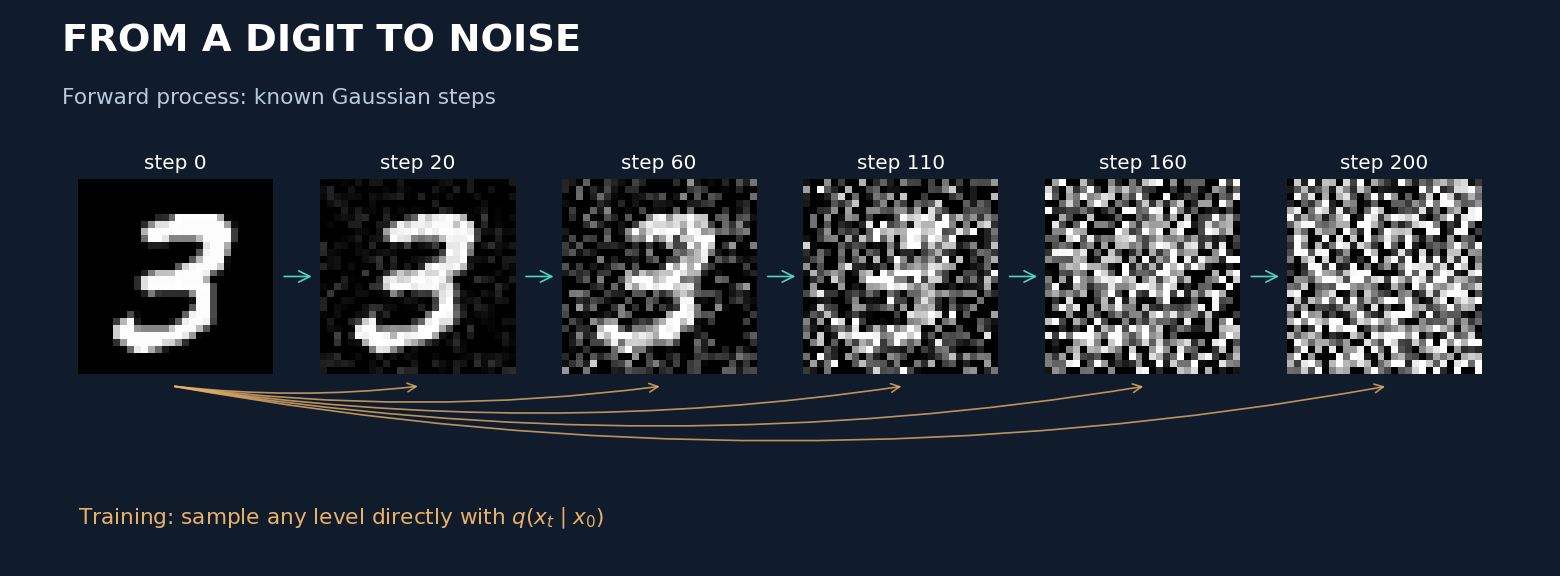

In [ ]:
from matplotlib.patches import FancyArrowPatch

def plot_forward_process():
    x0 = train_images[7:8].float() / 127.5 - 1
    g = torch.Generator().manual_seed(123)
    beta_cpu = schedule["beta"].cpu()
    selected = [0, 20, 60, 110, 160, T]
    states = {0: x0.clone()}; x = x0.clone()
    for t in range(T):
        z = torch.randn(x.shape, generator=g)
        x = (1-beta_cpu[t]).sqrt()*x + beta_cpu[t].sqrt()*z
        if t+1 in selected: states[t+1] = x.clone()
    fig = plt.figure(figsize=(13, 4.8), facecolor="#101b2c")
    fig.text(.04,.91,"FROM A DIGIT TO NOISE",color="white",fontsize=23,weight="bold")
    fig.text(.04,.82,"Forward process: known Gaussian steps",color="#b8cadc",fontsize=13)
    for i, step in enumerate(selected):
        left=.05+i*.155; ax=fig.add_axes([left,.35,.125,.34])
        ax.imshow(states[step][0,0].clamp(-1,1),cmap="gray",vmin=-1,vmax=1)
        ax.axis("off");ax.set_title(f"step {step}",color="white",fontsize=12)
        if i<5:
            fig.add_artist(FancyArrowPatch((left+.13,.52),(left+.152,.52),
                transform=fig.transFigure,arrowstyle="->",mutation_scale=17,color="#53d4bb"))
        if i>0:
            fig.add_artist(FancyArrowPatch((.11,.33),(left+.065,.33),
                transform=fig.transFigure,connectionstyle=f"arc3,rad={.05+i*.008}",
                arrowstyle="->",mutation_scale=13,color="#e8b169",alpha=.8))
    fig.text(.05,.09,r"Training: sample any level directly with $q(x_t\mid x_0)$",
             color="#e8b169",fontsize=13)
    plt.show()

plot_forward_process()

## 4. A small U-Net, built from scratch
**Discuss:** why must the same network receive the noise level? Why are skip connections useful for reconstructing spatial detail?

Resolution: **28 → 14 → 7 → 14 → 28**. Each residual block receives an embedding of the timestep. The output is a one-channel noise prediction with the same shape as the input. Digit labels never enter the model.

In [ ]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim=128):
        super().__init__(); self.dim = dim
        self.mlp = nn.Sequential(nn.Linear(dim, dim), nn.SiLU(), nn.Linear(dim, dim))
    def forward(self, t):
        frequencies = torch.exp(-math.log(10000) * torch.arange(
            self.dim//2, device=t.device).float() / (self.dim//2-1))
        angles = t.float()[:, None] * frequencies[None]
        return self.mlp(torch.cat([angles.sin(), angles.cos()], dim=1))

class ResBlock(nn.Module):
    def __init__(self, cin, cout, time_dim=128):
        super().__init__()
        self.first = nn.Sequential(nn.GroupNorm(8, cin), nn.SiLU(), nn.Conv2d(cin, cout, 3, padding=1))
        self.time = nn.Linear(time_dim, cout)
        self.second = nn.Sequential(nn.GroupNorm(8, cout), nn.SiLU(), nn.Conv2d(cout, cout, 3, padding=1))
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, emb):
        h = self.first(x) + self.time(F.silu(emb))[:, :, None, None]
        return self.skip(x) + self.second(h)

class TinyUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__(); self.time = TimeEmbedding()
        self.input = nn.Conv2d(1, base, 3, padding=1)
        self.enc1 = ResBlock(base, base)
        self.down1 = nn.Conv2d(base, base*2, 4, stride=2, padding=1)
        self.enc2 = ResBlock(base*2, base*2)
        self.down2 = nn.Conv2d(base*2, base*4, 4, stride=2, padding=1)
        self.mid1 = ResBlock(base*4, base*4); self.mid2 = ResBlock(base*4, base*4)
        self.up2 = nn.Conv2d(base*4, base*2, 3, padding=1)
        self.dec2 = ResBlock(base*4, base*2)
        self.up1 = nn.Conv2d(base*2, base, 3, padding=1)
        self.dec1 = ResBlock(base*2, base)
        self.output = nn.Sequential(nn.GroupNorm(8, base), nn.SiLU(), nn.Conv2d(base, 1, 3, padding=1))
    def forward(self, x, t):
        return self.forward_with_embedding(x, self.time(t))

    def forward_with_embedding(self, x, e):
        h1 = self.enc1(self.input(x), e)
        h2 = self.enc2(self.down1(h1), e)
        h = self.mid2(self.mid1(self.down2(h2), e), e)
        h = self.up2(F.interpolate(h, size=h2.shape[-2:], mode="nearest"))
        h = self.dec2(torch.cat([h, h2], 1), e)
        h = self.up1(F.interpolate(h, size=h1.shape[-2:], mode="nearest"))
        return self.output(self.dec1(torch.cat([h, h1], 1), e))

model = TinyUNet().to(device)
ema = copy.deepcopy(model).eval().requires_grad_(False)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")
assert model(torch.zeros(2,1,28,28,device=device), torch.tensor([0,T-1],device=device)).shape == (2,1,28,28)

Trainable parameters: 1,181,217


## 5. Training: one random time per image
**Try first:** write the three lines that create noisy inputs, predict noise, and calculate MSE.

$\mathcal L_{\mathrm{simple}}=\mathbb E\|\epsilon-\epsilon_\theta(x_t,t)\|^2$ is the simplified noise-prediction objective. It changes the timestep weights relative to the full variational bound.

EMA averages the model parameters for sampling. All samplers below use this **same** EMA copy. The checkpoint contains both networks, optimizer, schedule, completed updates and loss history. Loading is opt-in, so re-running the cell does not silently load an old experiment.

In [ ]:
RESUME = False
history = []
completed_steps = 0
if RESUME:
    checkpoint = torch.load(CHECKPOINT, map_location=device, weights_only=True)
    assert checkpoint["T"] == T and checkpoint["base"] == 32
    assert torch.allclose(checkpoint["beta"].to(device), schedule["beta"])
    model.load_state_dict(checkpoint["model"]); ema.load_state_dict(checkpoint["ema"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    history = checkpoint["history"]; completed_steps = checkpoint["steps"]

validation_rng = torch.Generator().manual_seed(909)
validation_t = torch.randint(T, (len(validation_images),), generator=validation_rng).to(device)
validation_noise = torch.randn(validation_images.shape, generator=validation_rng).to(device)

@torch.no_grad()
def validation_loss():
    total = 0.
    for x, t, eps in zip(validation_images.split(64), validation_t.split(64), validation_noise.split(64)):
        total += F.mse_loss(ema(q_sample(x,t,eps),t),eps).item()*len(x)
    return total/len(validation_images)

def save_checkpoint(step):
    torch.save({"model": model.state_dict(), "ema": ema.state_dict(),
                "optimizer": optimizer.state_dict(), "steps": step, "history": history,
                "T": T, "base": 32, "beta": schedule["beta"].cpu()}, CHECKPOINT)

model.train(); running = 0.; count = 0
synchronize(); started = time.perf_counter()
for step in trange(completed_steps, TRAIN_STEPS, desc="Train DDPM"):
    indices = torch.randint(len(train_images), (BATCH_SIZE,))
    x0 = train_images[indices].float().to(device)/127.5 - 1
    t = torch.randint(T, (len(x0),), device=device)
    eps = torch.randn_like(x0)
    prediction = model(q_sample(x0, t, eps), t)
    loss = F.mse_loss(prediction, eps)
    optimizer.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.)
    optimizer.step()
    with torch.no_grad():
        decay = min(.995, (1+step)/(10+step))
        for avg, current in zip(ema.parameters(), model.parameters()):
            avg.lerp_(current, 1-decay)
    running += loss.item(); count += 1
    if (step+1)%250 == 0 or step+1 == TRAIN_STEPS:
        val = validation_loss(); synchronize()
        elapsed = time.perf_counter()-started
        history.append({"step":step+1, "train":running/count, "validation":val})
        seconds_per_update = elapsed/(step+1-completed_steps)
        print(f"Step {step+1}: train={running/count:.4f}; val={val:.4f}; "
              f"{seconds_per_update:.3f} s/update; remaining ≈ "
              f"{seconds_per_update*(TRAIN_STEPS-step-1)/60:.1f} min")
        running=0.; count=0; save_checkpoint(step+1)
completed_steps = max(completed_steps, TRAIN_STEPS)
ema.eval()
print(f"Checkpoint: {CHECKPOINT.resolve()}")

Step 250: train=0.1513; val=0.0706; 0.138 s/update; remaining ≈ 2.9 min
Step 500: train=0.0688; val=0.0571; 0.122 s/update; remaining ≈ 2.0 min
Step 750: train=0.0602; val=0.0514; 0.117 s/update; remaining ≈ 1.5 min
Step 1000: train=0.0554; val=0.0480; 0.114 s/update; remaining ≈ 1.0 min
Step 1250: train=0.0521; val=0.0458; 0.112 s/update; remaining ≈ 0.5 min
Step 1500: train=0.0491; val=0.0440; 0.111 s/update; remaining ≈ 0.0 min
Checkpoint: mnist_ddpm_checkpoint.pt


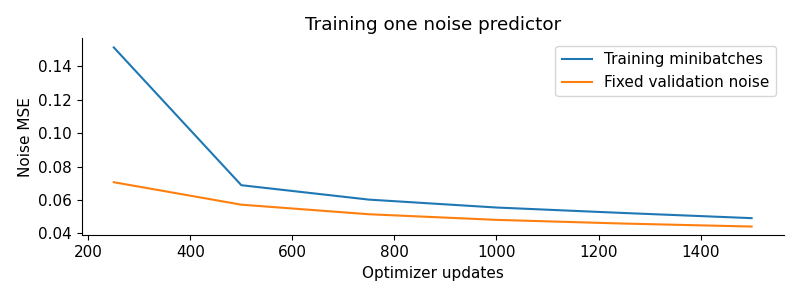

In [ ]:
loss_table = pd.DataFrame(history)
fig, ax = plt.subplots(figsize=(8,3))
ax.plot(loss_table.step, loss_table.train, label="Training minibatches")
ax.plot(loss_table.step, loss_table.validation, label="Fixed validation noise")
ax.set(xlabel="Optimizer updates", ylabel="Noise MSE", title="Training one noise predictor")
ax.legend(); plt.tight_layout(); plt.show()

### Picture 2 · Noisy input → estimated clean image
The network predicts noise. The formula converts that prediction to an estimate of the clean image. At very high noise, this estimate can be ambiguous. These are held-out images, not generated samples.

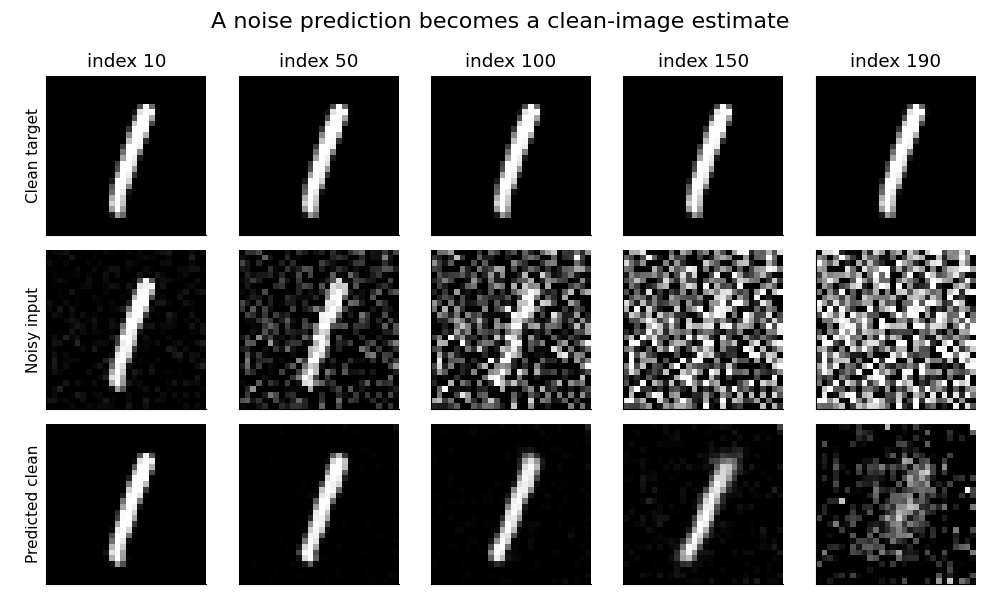

In [ ]:
@torch.no_grad()
def plot_denoising():
    clean = validation_images[5:6]
    g = torch.Generator().manual_seed(222)
    eps = torch.randn(clean.shape,generator=g).to(device)
    levels = [10, 50, 100, 150, 190]
    fig, axes = plt.subplots(3,len(levels),figsize=(10,6))
    for col, ti in enumerate(levels):
        t = torch.tensor([ti],device=device)
        noisy = q_sample(clean,t,eps); pred = ema(noisy,t)
        a = schedule["abar"][ti]
        recovered = ((noisy-(1-a).sqrt()*pred)/a.sqrt()).clamp(-1,1)
        for row, img in enumerate([clean,noisy,recovered]):
            axes[row,col].imshow(img[0,0].cpu(),cmap="gray",vmin=-1,vmax=1)
            axes[row,col].set_xticks([]);axes[row,col].set_yticks([])
        axes[0,col].set_title(f"index {ti}")
    for ax,label in zip(axes[:,0],["Clean target","Noisy input","Predicted clean"]): ax.set_ylabel(label)
    fig.suptitle("A noise prediction becomes a clean-image estimate",fontsize=16)
    plt.tight_layout();plt.show()
plot_denoising()

## 6. Two samplers, one trained model
**DDPM:** use every adjacent transition and posterior variance $\tilde\beta_t$. The last transition is deterministic.

**DDIM:** choose a decreasing subset of the trained times. For a jump $t\to s$, compute
$$
\widehat x_0=\frac{x_t-\sqrt{1-a_t}\epsilon_\theta(x_t,t)}{\sqrt{a_t}},\quad
\sigma_{t,s}=\eta\sqrt{\frac{1-a_s}{1-a_t}\left(1-\frac{a_t}{a_s}\right)},
$$
$$
x_s=\sqrt{a_s}\widehat x_0+\sqrt{1-a_s-\sigma_{t,s}^2}\widehat\epsilon+\sigma_{t,s}z,
\qquad a_t=\bar\alpha_t.
$$
`eta=0` is deterministic DDIM. Adjacent steps with `eta=1` reproduce the posterior-variance DDPM transition. **eta here is DDIM stochasticity, not the Langevin step size from Seminar 6.**

Both samplers clip their clean-image estimate to [-1,1]. After clipping, DDIM recomputes the compatible noise estimate. We apply the same convention to the comparison. This makes the adjacent-step equivalence test meaningful.

**Try first:** implement `predict_x0`, then explain why simply skipping DDPM loop iterations is incorrect.

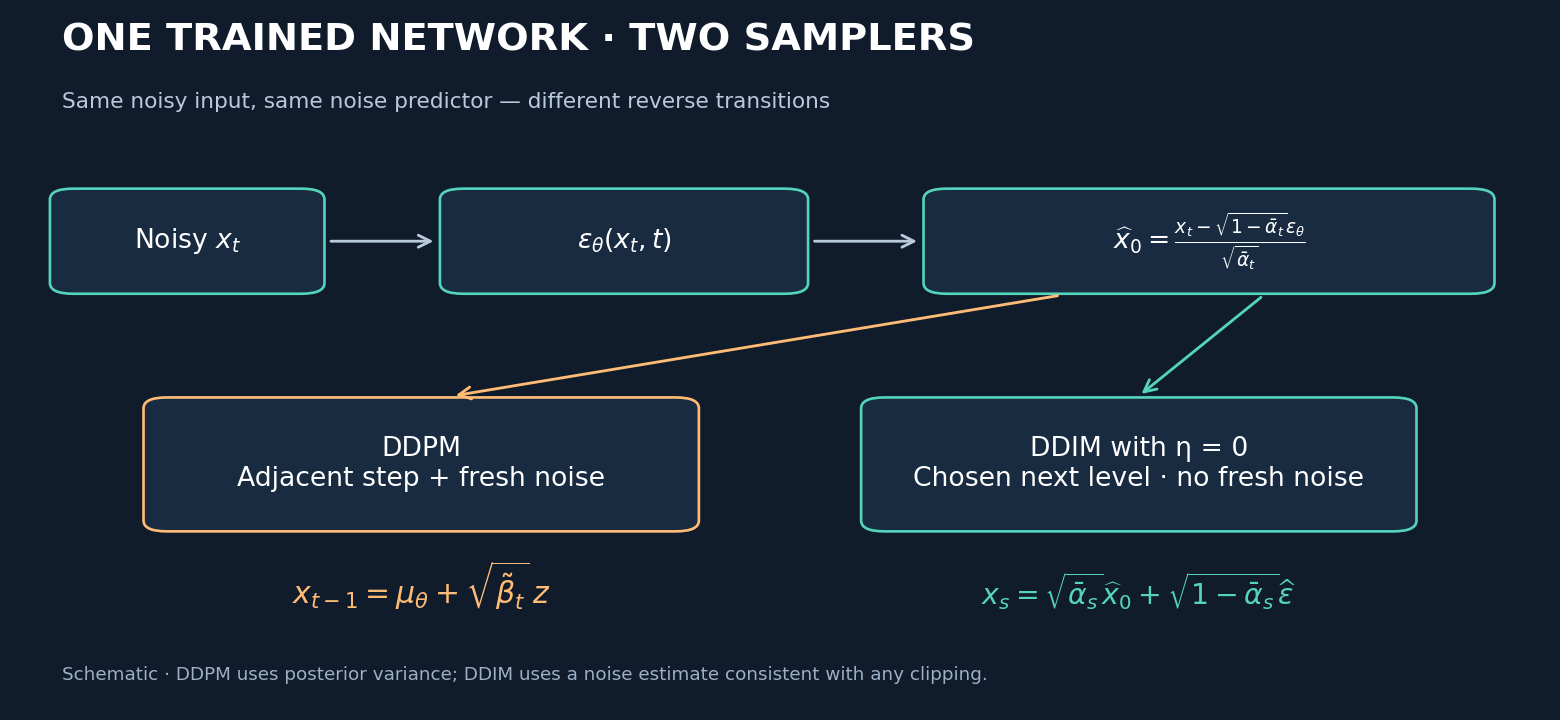

In [ ]:
from matplotlib.patches import FancyArrowPatch,FancyBboxPatch
fig=plt.figure(figsize=(13,6),facecolor='#101b2c');ax=fig.add_axes([0,0,1,1]);ax.set_xlim(0,1);ax.set_ylim(0,1);ax.axis('off')
ax.text(.04,.93,'ONE TRAINED NETWORK · TWO SAMPLERS',color='white',fontsize=23,weight='bold')
ax.text(.04,.85,'Same noisy input, same noise predictor — different reverse transitions',color='#b8cadc',fontsize=13)
def box(x,y,w,h,text,color='#53d4bb'):
 ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.008,rounding_size=0.015',facecolor='#182b41',edgecolor=color,lw=1.6))
 ax.text(x+w/2,y+h/2,text,ha='center',va='center',color='white',fontsize=16)
def arrow(x1,y1,x2,y2,color='#b8cadc'):
 ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle='->',mutation_scale=18,color=color,lw=1.7))
box(.04,.60,.16,.13,r'Noisy $x_t$');box(.29,.60,.22,.13,r'$\epsilon_\theta(x_t,t)$');box(.60,.60,.35,.13,r'$\widehat{x}_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta}{\sqrt{\bar\alpha_t}}$')
arrow(.21,.665,.28,.665);arrow(.52,.665,.59,.665)
box(.10,.27,.34,.17,'DDPM\nAdjacent step + fresh noise','#ffbc75');box(.56,.27,.34,.17,'DDIM with η = 0\nChosen next level · no fresh noise')
arrow(.68,.59,.29,.45,'#ffbc75');arrow(.81,.59,.73,.45,'#53d4bb')
ax.text(.27,.16,r'$x_{t-1}=\mu_\theta+\sqrt{\tilde\beta_t}\,z$',color='#ffbc75',fontsize=18,ha='center')
ax.text(.73,.16,r'$x_s=\sqrt{\bar\alpha_s}\widehat{x}_0+\sqrt{1-\bar\alpha_s}\widehat{\epsilon}$',color='#53d4bb',fontsize=17,ha='center')
ax.text(.04,.055,'Schematic · DDPM uses posterior variance; DDIM uses a noise estimate consistent with any clipping.',color='#9cb0c6',fontsize=11)
plt.show()

In [ ]:
def predict_x0(x, eps, t):
    a = schedule["abar"][t]
    return ((x - (1-a).sqrt()*eps)/a.sqrt()).clamp(-1,1)

def ddpm_step(x, eps, t, z):
    a = schedule["abar"][t]; prev = schedule["previous"][t]
    beta = schedule["beta"][t]; alpha = schedule["alpha"][t]
    clean = predict_x0(x,eps,t)
    mean = prev.sqrt()*beta/(1-a)*clean + alpha.sqrt()*(1-prev)/(1-a)*x
    return mean + schedule["posterior_var"][t].sqrt()*z

def ddim_step(x, eps, t, s, z, eta=0.):
    a = schedule["abar"][t]
    prev = schedule["abar"][s] if s >= 0 else torch.ones((),device=x.device)
    clean = predict_x0(x,eps,t)
    corrected_eps = (x-a.sqrt()*clean)/(1-a).sqrt()
    sigma = eta * ((1-prev)/(1-a)*(1-a/prev)).clamp_min(0).sqrt()
    return prev.sqrt()*clean + (1-prev-sigma.square()).clamp_min(0).sqrt()*corrected_eps + sigma*z

@torch.inference_mode()
def sample(network, initial_noise, method="ddim", steps=50, eta=0., seed=1234, capture=False, class_labels=None):
    if method not in {"ddpm","ddim"}: raise ValueError(method)
    if not 0 <= eta <= 1: raise ValueError("eta must be between 0 and 1")
    if not 1 <= steps <= T: raise ValueError("steps must lie in [1,T]")
    if method == "ddpm" and steps != T: raise ValueError("DDPM uses all adjacent steps")
    if class_labels is not None:
        class_labels = torch.as_tensor(class_labels, device=initial_noise.device)
        if class_labels.dtype != torch.long or class_labels.shape != (len(initial_noise),):
            raise ValueError("class_labels must be an int64 vector with one digit per image")
        if ((class_labels < 0) | (class_labels > 9)).any():
            raise ValueError("MNIST labels must be in [0,9]")
    times = np.rint(np.linspace(T-1,0,steps)).astype(int).tolist()
    assert len(times)==len(set(times))
    network.eval(); x = initial_noise.clone()
    # Generate all optional random increments before timing (portable seeded CPU RNG).
    g = torch.Generator().manual_seed(seed)
    increments = None
    if method == "ddpm" or eta > 0:
        increments = torch.randn((steps,*x.shape),generator=g).to(device)
    trajectory = [x[:8].cpu()] if capture else []
    labels = [T] if capture else []
    watch = set(np.rint(np.linspace(0,steps-1,6)).astype(int).tolist())
    synchronize(); start = time.perf_counter()
    for k,t in enumerate(times):
        time_batch = torch.full((len(x),),t,device=device,dtype=torch.long)
        eps = network(x,time_batch) if class_labels is None else network(x,time_batch,class_labels)
        z = increments[k] if increments is not None else torch.zeros_like(x)
        if method == "ddpm": x = ddpm_step(x,eps,t,z)
        else:
            s = times[k+1] if k+1<len(times) else -1
            x = ddim_step(x,eps,t,s,z,eta)
        if capture and k in watch:
            trajectory.append(x[:8].cpu());labels.append(times[k+1]+1 if k+1<len(times) else 0)
    synchronize(); elapsed = time.perf_counter()-start
    assert torch.isfinite(x).all()
    return x.cpu(), elapsed, trajectory, labels

### Check the math before looking at generated digits
These checks catch indexing, variance and timestep-jump mistakes. They do not establish that training has converged.

In [ ]:
check_rng = torch.Generator().manual_seed(77)
x = torch.randn((4,1,28,28),generator=check_rng).to(device)
eps = torch.randn(x.shape,generator=check_rng).to(device)
z = torch.randn(x.shape,generator=check_rng).to(device)
# Known noise must invert the forward corruption (before clipping).
t = torch.tensor([1,30,100,190],device=device)
a = extract(schedule["abar"],t)
back = (q_sample(x,t,eps)-(1-a).sqrt()*eps)/a.sqrt()
assert torch.allclose(x,back,atol=2e-5)
assert schedule["posterior_var"][0].item() == 0
# Same clipping convention, same random increment, adjacent timesteps.
for ti in [0,1,30,100,T-1]:
    assert torch.allclose(ddpm_step(x,eps,ti,z),ddim_step(x,eps,ti,ti-1,z,eta=1),atol=3e-4,rtol=3e-4), ti
print("Passed: forward inversion, final-step variance, DDPM/DDIM adjacent-step equivalence.")

Passed: forward inversion, final-step variance, DDPM/DDIM adjacent-step equivalence.


## 7. Comparison on the same initial noise
First compare **DDPM 200 vs DDIM 200** (equal network-call budget). Then reduce DDIM to 50, 20 and 10 calls. This isolates sampler choice from the speed–quality trade-off.

Each column starts from the same initial noise across rows. Different samplers may produce different digits: this is not a paired reconstruction task. Timing is the median of three warmed-up sampling runs, including model evaluation and updates, excluding random-increment preparation, plotting, and training. It is a device-specific measurement, not a universal speedup claim.

sampler  network_calls  seconds_median  seconds_min  seconds_max  speedup_vs_ddpm
   DDPM            200           3.368        3.131        3.605            1.000
   DDIM            200           2.981        2.939        3.022            1.130
   DDIM             50           0.774        0.726        0.823            4.348
   DDIM             20           0.292        0.291        0.292           11.542
   DDIM             10           0.146        0.146        0.147           23.007


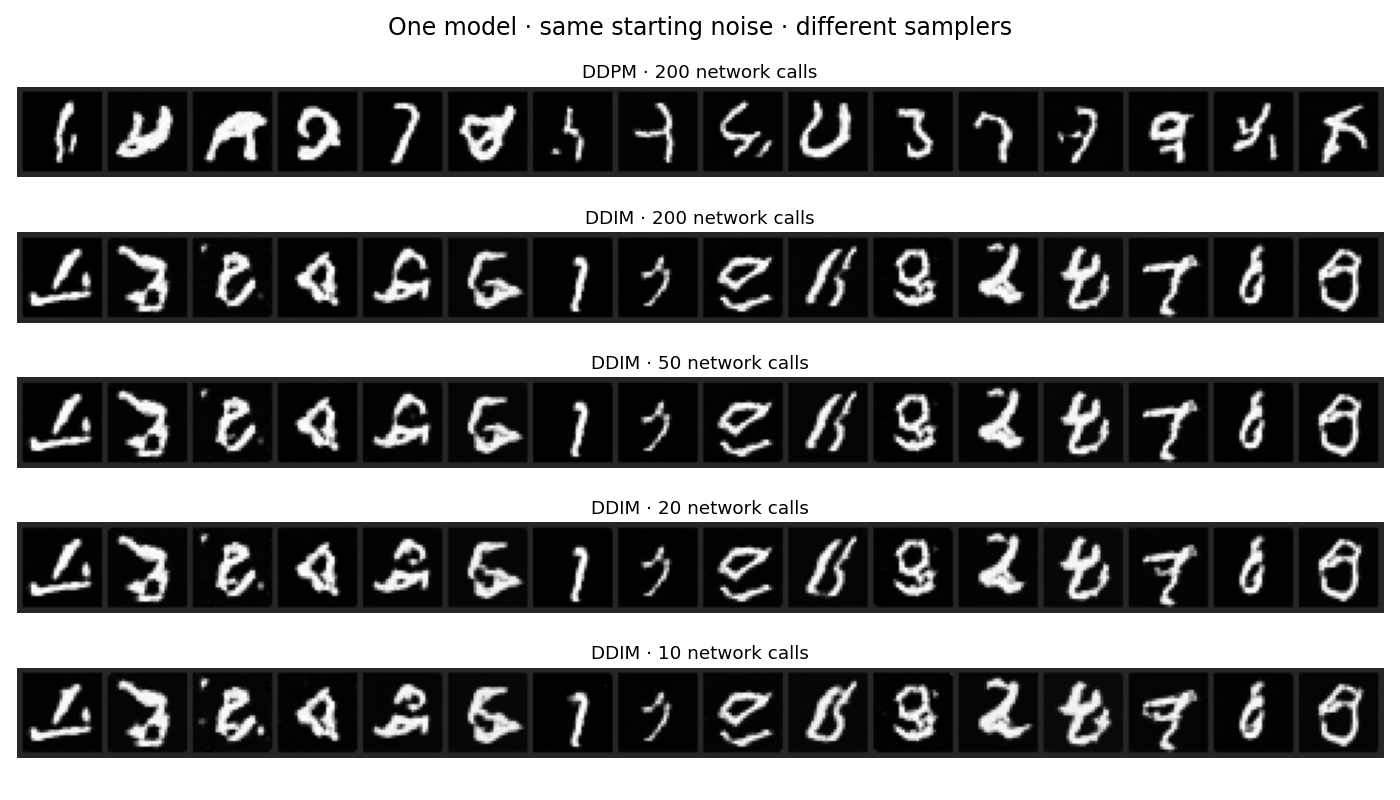

In [ ]:
N_SAMPLES = 64
TIMING_REPEATS = 3
initial_rng = torch.Generator().manual_seed(20261105)
initial_noise = torch.randn((N_SAMPLES,1,28,28),generator=initial_rng).to(device)
with torch.inference_mode():
    for _ in range(3): ema(initial_noise,torch.full((N_SAMPLES,),T-1,device=device,dtype=torch.long))
synchronize()
settings = [("DDPM", "ddpm", T), ("DDIM", "ddim", T),
            ("DDIM", "ddim", 50), ("DDIM", "ddim", 20), ("DDIM", "ddim", 10)]
results = {}; records = []
for name, method, steps in settings:
    times = []
    for repeat in range(TIMING_REPEATS):
        generated, seconds, _, _ = sample(ema,initial_noise,method,steps,seed=900+repeat)
        times.append(seconds)
        if repeat == 0: results[(name,steps)] = generated
    records.append({"sampler":name,"network_calls":steps,"seconds_median":np.median(times),
                    "seconds_min":min(times),"seconds_max":max(times)})
comparison = pd.DataFrame(records)
comparison["speedup_vs_ddpm"] = comparison.iloc[0].seconds_median/comparison.seconds_median
print(comparison.round(3).to_string(index=False))
fig, axes = plt.subplots(len(settings),1,figsize=(14,8))
for ax,(name,_,steps) in zip(axes,settings):
    show_grid(results[(name,steps)][:16],f"{name} · {steps} network calls",16,ax)
fig.suptitle("One model · same starting noise · different samplers",fontsize=17)
plt.tight_layout();plt.show()

### Picture 3 · Noise → digit, step by step
Each panel follows the same initial batch; rows are the same initial sample within that panel. State labels refer to the training noise schedule. These are **actual neural-network trajectories**, not interpolations between endpoint pictures.

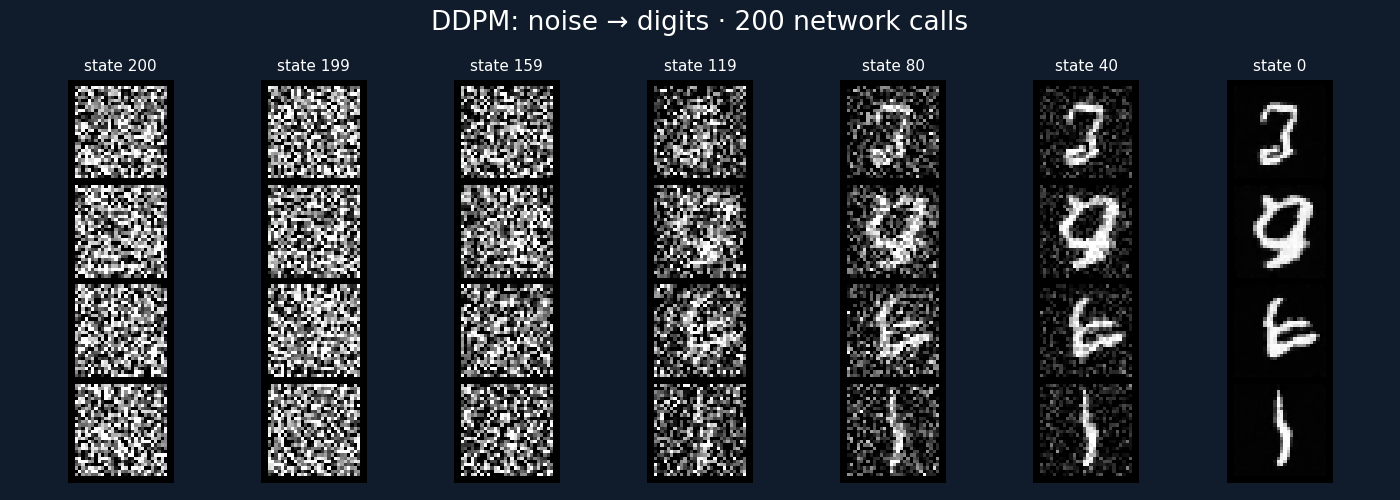

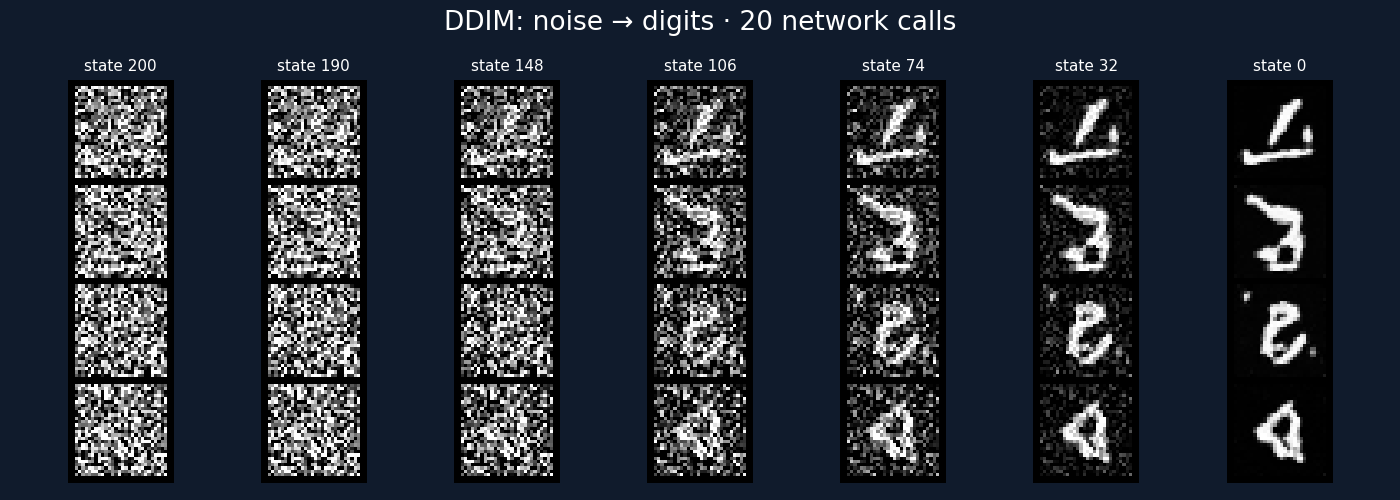

In [ ]:
trajectories = {}
for name,method,steps in [("DDPM","ddpm",T),("DDIM","ddim",20)]:
    final, _, states, labels = sample(ema,initial_noise[:8],method,steps,seed=900,capture=True)
    trajectories[name] = (states,labels)
    fig,axes = plt.subplots(1,len(states),figsize=(14,5),facecolor="#101b2c")
    for ax,state,label in zip(axes,states,labels):
        grid = make_grid((state[:4].clamp(-1,1)+1)/2,nrow=1,padding=2)
        ax.imshow(grid.permute(1,2,0));ax.axis("off")
        ax.set_title(f"state {label}",color="white",fontsize=11)
    fig.suptitle(f"{name}: noise → digits · {steps} network calls",color="white",fontsize=19)
    plt.tight_layout();plt.show()

## 8. Is DDIM really deterministic?
Keep the trained model **and initial noise** fixed. Changing the seed for additional sampler noise should change DDPM, but not DDIM with eta=0. Changing the initial noise changes deterministic DDIM too.

DDIM max difference: 0.0
DDPM mean absolute difference: 0.33055442571640015


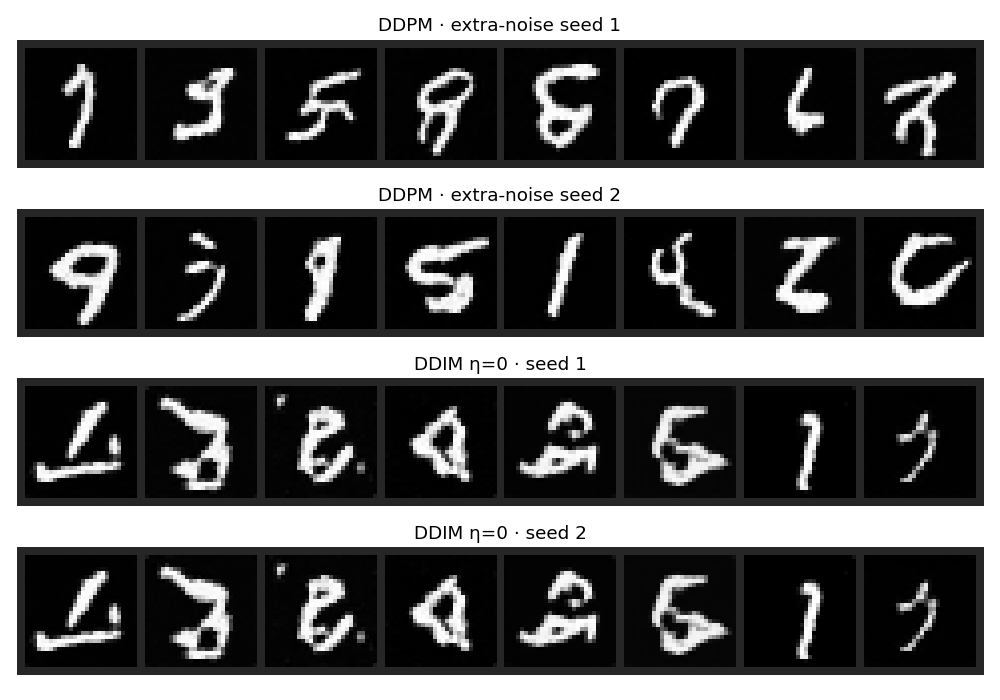

In [ ]:
probe = initial_noise[:8]
ddim_a,_,_,_ = sample(ema,probe,"ddim",20,seed=1)
ddim_b,_,_,_ = sample(ema,probe,"ddim",20,seed=2)
ddpm_a,_,_,_ = sample(ema,probe,"ddpm",T,seed=1)
ddpm_b,_,_,_ = sample(ema,probe,"ddpm",T,seed=2)
assert torch.allclose(ddim_a,ddim_b,atol=1e-5)
print("DDIM max difference:",(ddim_a-ddim_b).abs().max().item())
print("DDPM mean absolute difference:",(ddpm_a-ddpm_b).abs().mean().item())
fig,axes = plt.subplots(4,1,figsize=(10,7))
for ax,x,title in zip(axes,[ddpm_a,ddpm_b,ddim_a,ddim_b],
                      ["DDPM · extra-noise seed 1","DDPM · extra-noise seed 2",
                       "DDIM η=0 · seed 1","DDIM η=0 · seed 2"]):
    show_grid(x,title,8,ax)
plt.tight_layout();plt.show()

### Picture 4 · Actual DDPM and DDIM paths

Fix one initial noise image and project every intermediate image onto one fixed unit vector. Run each sampler three times, changing only the additional-noise seed. Both use **200 network calls** here.

DDPM paths can differ; all DDIM ($\eta=0$) paths overlap. This is one scalar diagnostic of actual image trajectories, not a 2D latent-space plot. Determinism does not imply a straight or necessarily smooth path. Comparing different DDIM step grids is a separate experiment.

Each trajectory panel uses its own vertical scale.

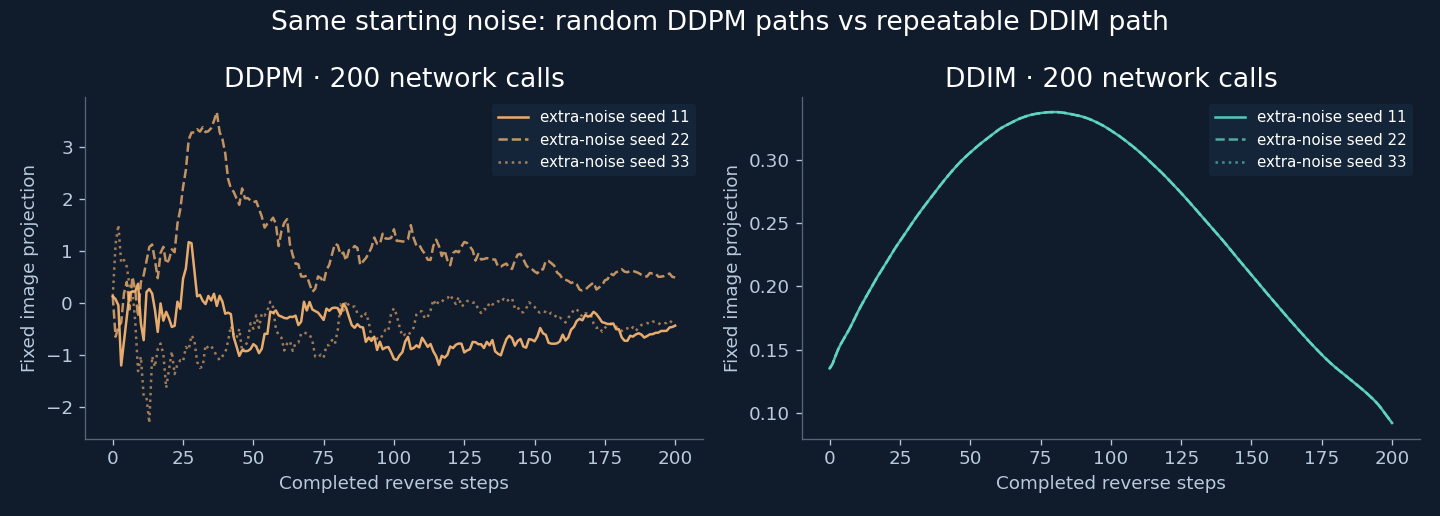

Lines join actual discrete states. DDIM curves overlap; determinism does not guarantee a straight or smooth path.


In [ ]:
# Plot a fixed scalar projection of an actual image trajectory.
# A curve is not a path through a 2D latent space: it is one diagnostic coordinate.
@torch.inference_mode()
def projected_trajectory(method, seed, initial, projection):
    g = torch.Generator().manual_seed(seed)
    zs = torch.randn((T,*initial.shape),generator=g).to(device)
    x = initial.clone(); values = [(x*projection).sum().item()]
    for t in range(T-1,-1,-1):
        eps = ema(x,torch.full((len(x),),t,device=device,dtype=torch.long))
        if method == "ddpm": x = ddpm_step(x,eps,t,zs[T-1-t])
        else: x = ddim_step(x,eps,t,t-1,zs[T-1-t],eta=0.)
        values.append((x*projection).sum().item())
    return np.asarray(values), x.cpu()

projection_rng = torch.Generator().manual_seed(801)
projection = torch.randn((1,1,28,28),generator=projection_rng).to(device)
projection = projection/projection.norm()
fig, axes = plt.subplots(1,2,figsize=(12,4.3),facecolor="#101b2c")
path_results = {}
for ax,method,color in zip(axes,["ddpm","ddim"],["#ffbc75","#61dac5"]):
    ax.set_facecolor("#101b2c"); path_results[method]=[]
    for i,seed in enumerate([11,22,33]):
        values, final = projected_trajectory(method,seed,initial_noise[:1],projection)
        path_results[method].append(values)
        ax.plot(np.arange(T+1),values,color=color,alpha=.9-i*.15,
                linestyle=["-","--",":"][i],label=f"extra-noise seed {seed}",lw=1.5)
    ax.set_title(f"{method.upper()} · {T} network calls",color="white",fontsize=16)
    ax.set_xlabel("Completed reverse steps",color="#b8cadc")
    ax.set_ylabel("Fixed image projection",color="#b8cadc")
    ax.tick_params(colors="#b8cadc")
    for spine in ax.spines.values():spine.set_color("#52667c")
    ax.legend(facecolor="#17283d",labelcolor="white",edgecolor="none",fontsize=9)
fig.suptitle("Same starting noise: random DDPM paths vs repeatable DDIM path",color="white",fontsize=16)
plt.tight_layout();plt.show()
assert np.allclose(path_results["ddim"][0],path_results["ddim"][1],atol=1e-5)
print("Lines join actual discrete states. DDIM curves overlap; determinism does not guarantee a straight or smooth path.")


## 9. Experiments to run in class
Change **one variable at a time** and reuse the same checkpoint.

1. **Number of DDIM calls:** 10, 20, 50, 200. Compare digit legibility, broken strokes, diversity and median runtime. Is ten times fewer calls exactly ten times faster?
2. **Stochasticity:** run 20-step DDIM with `eta=0`, `0.5`, `1`. Fix the initial noise, then change the sampler seed. At 20 steps, eta=1 is a stochastic skipped-step sampler, not the original 200-step DDPM.
3. **Training budget:** save outputs at 1,000 and 5,000 updates. Keep all sampling settings fixed. Does a lower noise MSE always improve every displayed sample?
4. **Clipping (advanced):** remove clean-estimate clipping from both step functions, retain the same convention, and rerun the equivalence check. Inspect intermediate states near the noisiest levels.

Do not call pixel MSE between DDPM and DDIM outputs a quality metric: neither generated image is ground truth for the other. A 64-image grid is a qualitative diagnostic, not a distribution-quality benchmark. The smaller model and shortened schedule are chosen for teaching.

**Takeaway:** the trained network estimates noise; the sampler decides how to use that estimate. DDIM changes the sampling path and can reduce the number of network evaluations without retraining.

## 10. Choose the digit: class-conditional diffusion

**Question:** can the same initial noise become a 0, a 3, or an 8 just by changing the requested label?

We now learn $p_\theta(x_0\mid y)$, with $y\in\{0,\ldots,9\}$. The forward noise schedule and both sampler formulas stay the same. The network now predicts $\epsilon_\theta(x_t,t,y)$:

$$
e(t,y)=e_{\mathrm{time}}(t)+e_{\mathrm{class}}(y),\qquad
\mathcal L_{\mathrm{cond}}=\mathbb E_{(x_0,y),t,\epsilon}
\left\|\epsilon-\epsilon_\theta\!\left(\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,t,y\right)\right\|_2^2.
$$

A learned lookup table maps each digit to a 128-dimensional embedding. We add it to the time embedding passed to every residual block. The label comes from the **same training example** as the clean image, and stays fixed throughout sampling. Passing labels only at sampling time would not teach a previously unconditional model what they mean.

**Route:** run the earlier setup, data, schedule, model, unconditional training and sampler cells, then this section. The default experiment starts from the earlier trained EMA weights and trains all conditional weights for another 2,000 updates. `CONDITIONAL_WARM_START=False` instead initializes from scratch; allow a larger training budget. This is direct conditioning: no classifier, label dropout or classifier-free guidance is used.

Implementation reference: [PyTorch Embedding](https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html).

**Saved local run:** 2,000 conditional updates with batch size 64 on Apple MPS, initialized from the earlier unconditional EMA after 1,500 updates. The default full Colab run starts from the preceding 5,000-update unconditional model. The saved images below are actual generated results, not selected target images; timing values are local measurements.

In [ ]:
class ConditionalUNet(TinyUNet):
    def __init__(self, base=32):
        super().__init__(base)
        self.class_embedding = nn.Embedding(10, 128)
        # Default unit-scale embeddings give distinct class signals from the start.

    def forward(self, x, t, y):
        e = self.time(t) + self.class_embedding(y)
        return self.forward_with_embedding(x, e)

CONDITIONAL_SEED = 20261105
CONDITIONAL_STEPS = 2000
CONDITIONAL_BATCH_SIZE = 64
CONDITIONAL_WARM_START = True
CONDITIONAL_RESUME = False
CONDITIONAL_CHECKPOINT = Path("mnist_conditional_ddpm_checkpoint.pt")

torch.manual_seed(CONDITIONAL_SEED)
conditional_model = ConditionalUNet().to(device)
if CONDITIONAL_WARM_START and not CONDITIONAL_RESUME:
    loaded = conditional_model.load_state_dict(ema.state_dict(), strict=False)
    assert loaded.missing_keys == ["class_embedding.weight"] and not loaded.unexpected_keys
conditional_ema = copy.deepcopy(conditional_model).eval().requires_grad_(False)
conditional_optimizer = torch.optim.Adam(conditional_model.parameters(), lr=LEARNING_RATE)
conditional_history = []
conditional_completed = 0
conditional_init = "unconditional EMA" if CONDITIONAL_WARM_START else "random weights"
if CONDITIONAL_RESUME:
    restored = torch.load(CONDITIONAL_CHECKPOINT, map_location=device, weights_only=True)
    assert restored["kind"] == "class_conditional" and restored["T"] == T
    assert torch.allclose(restored["beta"].to(device), schedule["beta"])
    conditional_model.load_state_dict(restored["model"])
    conditional_ema.load_state_dict(restored["ema"])
    conditional_optimizer.load_state_dict(restored["optimizer"])
    conditional_history = restored["history"]; conditional_completed = restored["steps"]
    conditional_init = restored["initialization"]
train_labels = train_set.targets
conditional_validation_labels = test_set.targets[:len(validation_images)].to(device)
print(f"Conditional model: {sum(p.numel() for p in conditional_model.parameters()):,} parameters")
print(f"Initialization: {conditional_init}; completed conditional updates: {conditional_completed}")

Conditional model: 1,182,497 parameters
Initialization: unconditional EMA; completed conditional updates: 0


### Training with image–label pairs

**Find the change:** the noise target is unchanged. The extra information is `y = train_labels[indices]`, passed to the network along with the noisy image and time.

Validation uses the same fixed images, noise and timesteps at every checkpoint. Its MSE is a denoising diagnostic, not an accuracy measure for generated digits. The unconditional network remains available as `ema`; conditional weights are stored separately.

In [ ]:
conditional_val_rng = torch.Generator().manual_seed(909)
conditional_val_t = torch.randint(T,(len(validation_images),),generator=conditional_val_rng).to(device)
conditional_val_noise = torch.randn(validation_images.shape,generator=conditional_val_rng).to(device)

@torch.no_grad()
def conditional_validation_loss():
    total = 0.
    batches = zip(validation_images.split(64),conditional_validation_labels.split(64),
                  conditional_val_t.split(64),conditional_val_noise.split(64))
    for x,y,t,eps in batches:
        total += F.mse_loss(conditional_ema(q_sample(x,t,eps),t,y),eps).item()*len(x)
    return total/len(validation_images)

def save_conditional_checkpoint(step):
    torch.save({"kind":"class_conditional", "T":T, "beta":schedule["beta"].cpu(),
                "model":conditional_model.state_dict(), "ema":conditional_ema.state_dict(),
                "optimizer":conditional_optimizer.state_dict(), "steps":step,
                "history":conditional_history, "initialization":conditional_init},
               CONDITIONAL_CHECKPOINT)

conditional_model.train(); running = 0.; count = 0
synchronize(); conditional_started = time.perf_counter()
for step in trange(conditional_completed,CONDITIONAL_STEPS,desc="Train conditional DDPM"):
    indices = torch.randint(len(train_images),(CONDITIONAL_BATCH_SIZE,))
    x0 = train_images[indices].float().to(device)/127.5 - 1
    y = train_labels[indices].to(device)
    t = torch.randint(T,(len(x0),),device=device)
    eps = torch.randn_like(x0)
    loss = F.mse_loss(conditional_model(q_sample(x0,t,eps),t,y),eps)
    conditional_optimizer.zero_grad(set_to_none=True); loss.backward()
    nn.utils.clip_grad_norm_(conditional_model.parameters(),1.)
    conditional_optimizer.step()
    with torch.no_grad():
        decay = min(.995,(1+step)/(10+step))
        for avg,current in zip(conditional_ema.parameters(),conditional_model.parameters()):
            avg.lerp_(current,1-decay)
    running += loss.item(); count += 1
    if (step+1)%250 == 0 or step+1 == CONDITIONAL_STEPS:
        val = conditional_validation_loss(); synchronize()
        elapsed = time.perf_counter()-conditional_started
        conditional_history.append({"step":step+1,"train":running/count,"validation":val})
        print(f"Conditional update {step+1}: train={running/count:.4f}; val={val:.4f}; "
              f"{elapsed/(step+1-conditional_completed):.3f} s/update")
        running=0.; count=0; save_conditional_checkpoint(step+1)
conditional_completed = max(conditional_completed,CONDITIONAL_STEPS)
conditional_ema.eval()
print(f"Saved: {CONDITIONAL_CHECKPOINT.name}")

Conditional update 250: train=0.0597; val=0.0453; 0.122 s/update
Conditional update 500: train=0.0488; val=0.0425; 0.155 s/update
Conditional update 750: train=0.0470; val=0.0411; 0.166 s/update
Conditional update 1000: train=0.0464; val=0.0402; 0.171 s/update
Conditional update 1250: train=0.0453; val=0.0395; 0.174 s/update
Conditional update 1500: train=0.0440; val=0.0389; 0.177 s/update
Conditional update 1750: train=0.0447; val=0.0384; 0.178 s/update
Conditional update 2000: train=0.0432; val=0.0381; 0.179 s/update
Saved: mnist_conditional_ddpm_checkpoint.pt


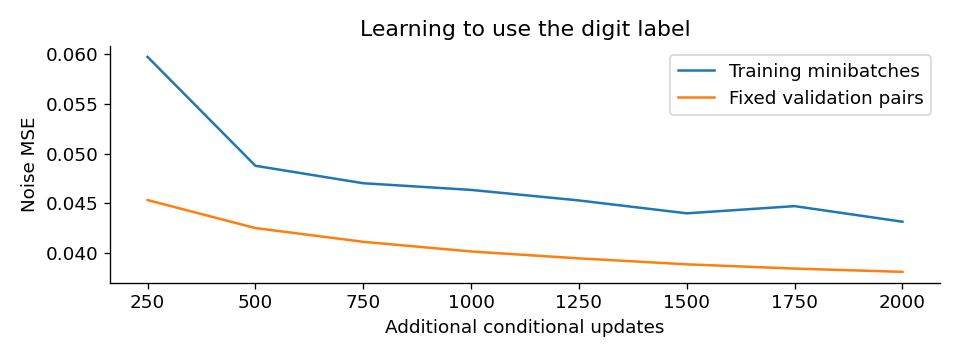

In [ ]:
conditional_loss_table = pd.DataFrame(conditional_history)
fig,ax = plt.subplots(figsize=(8,3))
ax.plot(conditional_loss_table.step,conditional_loss_table.train,label="Training minibatches")
ax.plot(conditional_loss_table.step,conditional_loss_table.validation,label="Fixed validation pairs")
ax.set(xlabel="Additional conditional updates",ylabel="Noise MSE",title="Learning to use the digit label")
ax.legend();plt.tight_layout();plt.show()

### Same starting noise, different requested digits

Rows request digits 0–9. Each column uses **exactly the same initial noise across all rows**; columns use six different noise images. Deterministic DDIM with 50 calls adds no fresh noise, so the only changed input within a column is the label.

**Inspect:** does changing the label change the digit? Does changing the initial noise preserve the requested digit while varying its appearance? Label control does not guarantee perfect digits or identical handwriting style across classes.

**In the saved run:** labels change the generated class, but some images remain ambiguous or miss the request (including examples in the 7/8 rows). Inspect failures as well as successful samples. Increasing `CONDITIONAL_STEPS` and resuming training is an additional experiment; a lower noise MSE alone does not establish perfect class control.

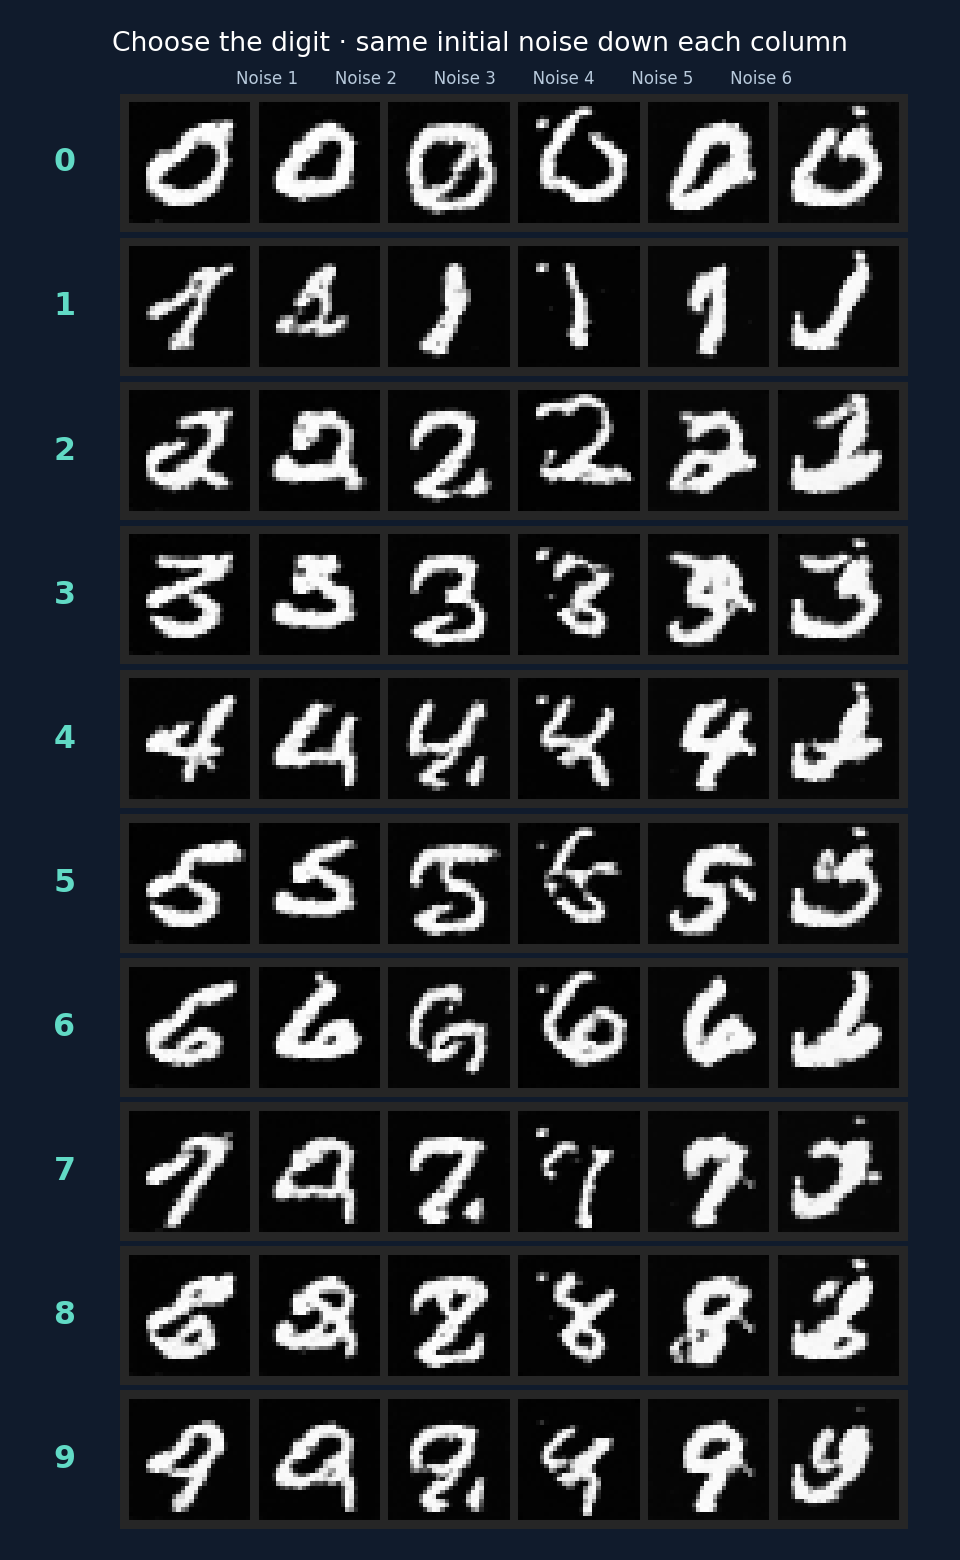

In [ ]:
conditional_grid_rng = torch.Generator().manual_seed(2048)
noise_columns = torch.randn((6,1,28,28),generator=conditional_grid_rng).to(device)
label_grid = torch.arange(10,device=device).repeat_interleave(6)
noise_grid = noise_columns.repeat(10,1,1,1)
conditioned_grid,_,_,_ = sample(conditional_ema,noise_grid,"ddim",50,class_labels=label_grid)
fig,axes = plt.subplots(10,1,figsize=(8,13),facecolor="#101b2c")
for digit,ax in enumerate(axes):
    show_grid(conditioned_grid[digit*6:(digit+1)*6],"",6,ax)
    ax.text(-.07,.5,str(digit),transform=ax.transAxes,color="#61dac5",
            fontsize=19,weight="bold",ha="center",va="center")
fig.suptitle("Choose the digit · same initial noise down each column",color="white",fontsize=16)
axes[0].set_title("Noise 1       Noise 2       Noise 3       Noise 4       Noise 5       Noise 6",
                  color="#b8cadc",fontsize=10)
fig.subplots_adjust(top=.94,bottom=.02,left=.09,right=.98,hspace=.04)
plt.show()

### Conditional DDPM vs DDIM

Keep the conditional weights, ten requested labels and ten starting noise images fixed. First compare 200 calls with 200; then reduce DDIM to 20. The repeated runtimes use the same convention as Section 7. The extra DDPM noise can change the exact output even when the starting noise and label match.

**Inspect separately:** requested-digit agreement, legibility, diversity, and speed. These grids are qualitative diagnostics; they do not establish a population-level accuracy or quality score.

sampler  calls  batch_size  seconds_median
   DDPM    200          10           3.134
   DDIM    200          10           2.640
   DDIM     20          10           0.260


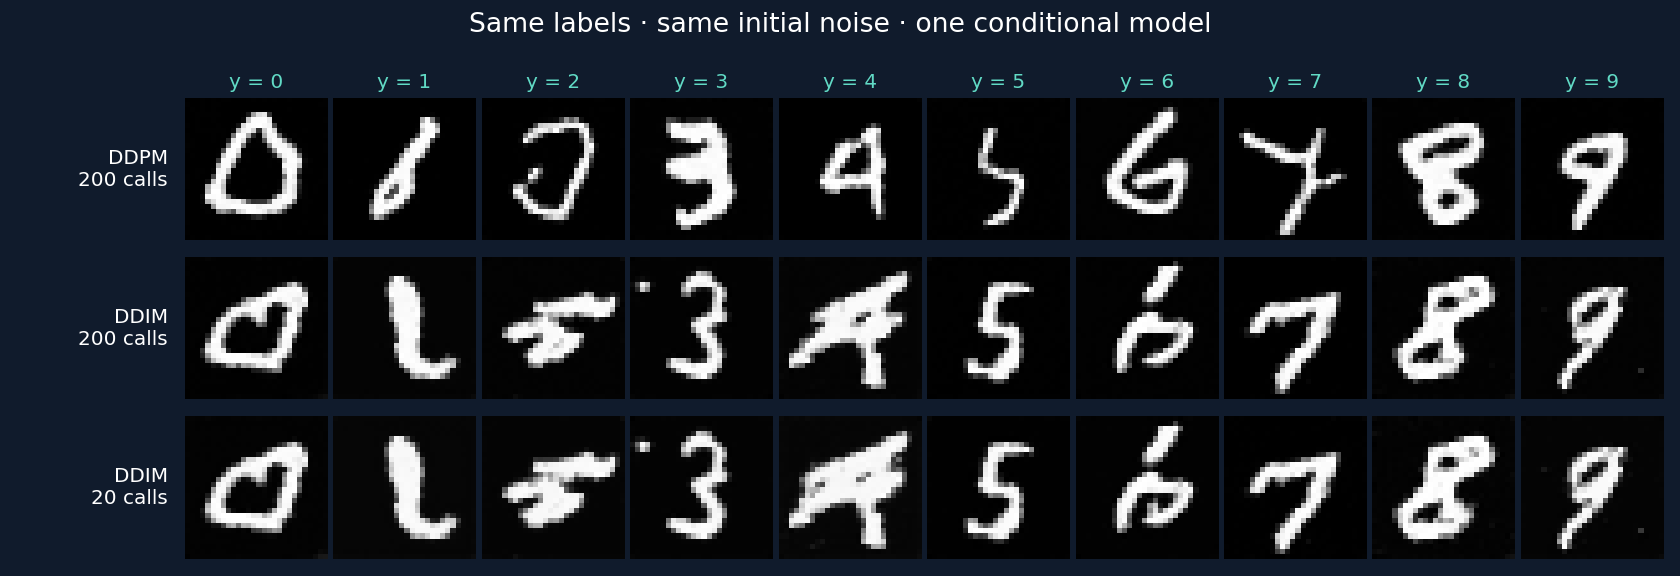

In [ ]:
conditional_compare_rng = torch.Generator().manual_seed(83)
conditional_compare_noise = torch.randn((10,1,28,28),generator=conditional_compare_rng).to(device)
requested_digits = torch.arange(10,device=device)
conditional_results = {}; conditional_records = []
with torch.inference_mode():
    for _ in range(3):
        conditional_ema(conditional_compare_noise,torch.full((10,),T-1,device=device,dtype=torch.long),requested_digits)
synchronize()
for name,method,steps in [("DDPM","ddpm",T),("DDIM","ddim",T),("DDIM","ddim",20)]:
    durations = []
    for repeat in range(3):
        generated,seconds,_,_ = sample(conditional_ema,conditional_compare_noise,method,steps,
                                       seed=800+repeat,class_labels=requested_digits)
        durations.append(seconds)
        if repeat == 0: conditional_results[(name,steps)] = generated
    conditional_records.append({"sampler":name,"calls":steps,"batch_size":10,
                                "seconds_median":np.median(durations)})
print(pd.DataFrame(conditional_records).round(3).to_string(index=False))
fig,axes = plt.subplots(3,10,figsize=(14,4.8),facecolor="#101b2c")
for row,((name,steps),images) in enumerate(conditional_results.items()):
    for digit,ax in enumerate(axes[row]):
        ax.imshow(images[digit,0],cmap="gray",vmin=-1,vmax=1);ax.axis("off")
        if row==0:ax.set_title(f"y = {digit}",color="#61dac5",fontsize=12)
    axes[row,0].text(-.12,.5,f"{name}\n{steps} calls",transform=axes[row,0].transAxes,
                     ha="right",va="center",color="white",fontsize=12)
fig.suptitle("Same labels · same initial noise · one conditional model",color="white",fontsize=16)
fig.subplots_adjust(left=.11,right=.99,top=.83,bottom=.03,hspace=.12,wspace=.04)
plt.show()

### Verify conditioning and try your own digit

Changing the label should affect the prediction; gradients must reach the label embedding during training. Repeating deterministic DDIM with identical noise and labels must reproduce the output. These are implementation checks, not a guarantee that every generated digit matches its requested class.

Passed: label influence, embedding gradients, conditional DDIM repeatability.


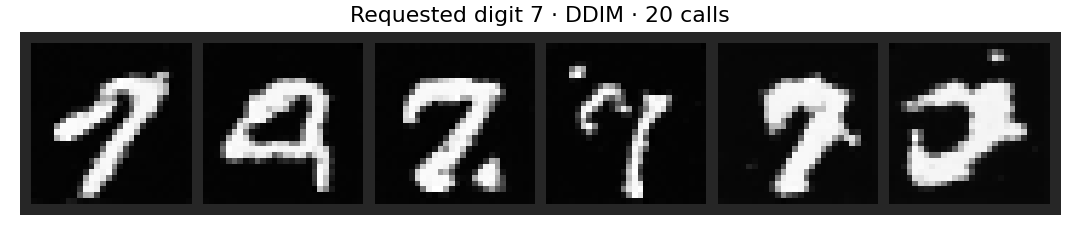

In [ ]:
DIGIT = 7  # Change to any integer from 0 to 9, then rerun this cell.

check_x = noise_columns[:2]
check_t = torch.full((2,),T//2,device=device,dtype=torch.long)
with torch.no_grad():
    pred_zero = conditional_ema(check_x,check_t,torch.zeros(2,device=device,dtype=torch.long))
    pred_one = conditional_ema(check_x,check_t,torch.ones(2,device=device,dtype=torch.long))
assert not torch.allclose(pred_zero,pred_one), "The network appears to ignore class labels"
conditional_optimizer.zero_grad(set_to_none=True)
conditional_model(check_x,check_t,torch.tensor([0,1],device=device)).square().mean().backward()
assert conditional_model.class_embedding.weight.grad.abs().sum()>0
conditional_optimizer.zero_grad(set_to_none=True)
fixed_y = torch.tensor([3,8],device=device)
a,_,_,_ = sample(conditional_ema,check_x,"ddim",20,seed=1,class_labels=fixed_y)
b,_,_,_ = sample(conditional_ema,check_x,"ddim",20,seed=2,class_labels=fixed_y)
assert torch.allclose(a,b,atol=1e-6)
print("Passed: label influence, embedding gradients, conditional DDIM repeatability.")

assert isinstance(DIGIT,int) and 0 <= DIGIT <= 9
chosen_labels = torch.full((len(noise_columns),),DIGIT,device=device,dtype=torch.long)
chosen,_,_,_ = sample(conditional_ema,noise_columns,"ddim",20,class_labels=chosen_labels)
fig, ax = plt.subplots(figsize=(9,2))
show_grid(chosen,f"Requested digit {DIGIT} · DDIM · 20 calls",6,ax)
plt.tight_layout();plt.show()

**Discuss:** an unconditional model samples a digit on its own; a conditional model samples an image for the requested digit. The label specifies the class, while initial noise supplies variation. The class embedding and all other conditional weights are learned from paired images and labels.

**Extensions:** (1) hold noise fixed and change `DIGIT`; (2) hold `DIGIT` fixed and change the noise seed; (3) compare 10/20/50 DDIM calls for the same label; (4) train a separate model with shuffled image–label pairs to test why correct pairing matters. Merely requesting a different label from a correctly trained model is not the same as training with mismatched labels.

**Keep the comparison fair:** this conditional model has extra training updates. Its agreement with labels tests control; any improvement in visual quality over the earlier unconditional model cannot be attributed to conditioning alone without matching training budgets.

## 11. Classifier-free guidance: how strongly should we ask?

Train the same network both with a digit label and with a special **null condition** $\varnothing$. During training, independently replace 20% of labels with the null token. Do not change the image or noise target.

At sampling time combine two predictions from this **one jointly trained model**:

$$
\widehat\epsilon_s(x_t,t,y)=\epsilon_\theta(x_t,t,\varnothing)
+s\,[\epsilon_\theta(x_t,t,y)-\epsilon_\theta(x_t,t,\varnothing)].
$$

- $s=0$: unconditional prediction, ignoring the requested digit.
- $s=1$: ordinary conditional prediction from the CFG model.
- $s>1$: extrapolate the effect of the condition.

Our scale is $s=1+w$ in the paper's convention $(1+w)\epsilon_{\mathrm{cond}}-w\epsilon_{\mathrm{uncond}}$. Higher guidance can trade diversity for fidelity, but does not guarantee a monotonic improvement.

Source: [Ho & Salimans, Classifier-Free Diffusion Guidance (2022)](https://arxiv.org/abs/2207.12598).

**Run:** continue after Section 10. We initialize from its conditional EMA, add one trainable null embedding, and jointly train both branches for 2,000 further updates. The sweep uses this new model for **every** scale, including $s=1$. Comparing to an earlier checkpoint would confound guidance with extra training. A zero embedding alone is not a trained unconditional branch.

**Saved local run:** 2,000 joint CFG updates, batch size 64, 20% label dropout, initialized from the Section 10 conditional EMA (2,000 updates after 1,500 unconditional updates). All scales use one joint EMA checkpoint, 50 DDIM steps, and 64 samples per digit. Evaluation classifier: two epochs on real MNIST training images. Everything was executed on Apple MPS; the earlier Colab defaults use more unconditional training.

In [ ]:
NULL_LABEL = 10
CFG_DROP_PROB = 0.20
CFG_STEPS = 2000
CFG_BATCH_SIZE = 64
CFG_RESUME = False
CFG_CHECKPOINT = Path("mnist_cfg_checkpoint.pt")
torch.manual_seed(20261106)

class CFGUNet(ConditionalUNet):
    def __init__(self):
        super().__init__()
        self.class_embedding = nn.Embedding(11,128)

cfg_model = CFGUNet().to(device)
if not CFG_RESUME:
    initial_state = {k:v for k,v in conditional_ema.state_dict().items() if k != "class_embedding.weight"}
    loaded = cfg_model.load_state_dict(initial_state,strict=False)
    assert loaded.missing_keys == ["class_embedding.weight"] and not loaded.unexpected_keys
    with torch.no_grad():
        cfg_model.class_embedding.weight[:10].copy_(conditional_ema.class_embedding.weight)
        cfg_model.class_embedding.weight[NULL_LABEL].zero_()
cfg_ema = copy.deepcopy(cfg_model).eval().requires_grad_(False)
cfg_optimizer = torch.optim.Adam(cfg_model.parameters(),lr=LEARNING_RATE)
cfg_history = []; cfg_completed = 0
if CFG_RESUME:
    state = torch.load(CFG_CHECKPOINT,map_location=device,weights_only=True)
    assert state["kind"]=="classifier_free" and state["T"]==T
    assert state["drop_prob"]==CFG_DROP_PROB
    assert torch.allclose(state["beta"].to(device),schedule["beta"])
    cfg_model.load_state_dict(state["model"]);cfg_ema.load_state_dict(state["ema"])
    cfg_optimizer.load_state_dict(state["optimizer"])
    cfg_history=state["history"];cfg_completed=state["steps"]

def drop_labels(y,probability):
    if not 0 <= probability <= 1:raise ValueError("Drop probability must lie in [0,1]")
    mask = torch.rand(y.shape,device=y.device)<probability
    return torch.where(mask,torch.full_like(y,NULL_LABEL),y),mask

probe_labels = torch.arange(10,device=device)
assert torch.equal(drop_labels(probe_labels,0.)[0],probe_labels)
assert (drop_labels(probe_labels,1.)[0]==NULL_LABEL).all()
print("CFG initialization ready; null label is 10, not the digit 0.")

CFG initialization ready; null label is 10, not the digit 0.


### Joint Training

Compare conditional and null validation losses on the **same** fixed noisy images. Null validation deliberately withholds the label. Both tasks use the ordinary noise MSE. The observed dropout fraction should be close to 20%; the checkpoint stores the model, EMA, optimizer, schedule and dropout probability.

Update 250: train=0.0443; conditional=0.0380; null=0.0398; label dropout=19.9%
Update 500: train=0.0432; conditional=0.0377; null=0.0390; label dropout=20.2%
Update 750: train=0.0432; conditional=0.0373; null=0.0385; label dropout=20.0%
Update 1000: train=0.0427; conditional=0.0371; null=0.0383; label dropout=19.9%
Update 1250: train=0.0424; conditional=0.0370; null=0.0382; label dropout=19.9%
Update 1500: train=0.0417; conditional=0.0368; null=0.0379; label dropout=20.0%
Update 1750: train=0.0419; conditional=0.0366; null=0.0376; label dropout=20.0%
Update 2000: train=0.0417; conditional=0.0363; null=0.0374; label dropout=20.0%
Saved mnist_cfg_checkpoint.pt


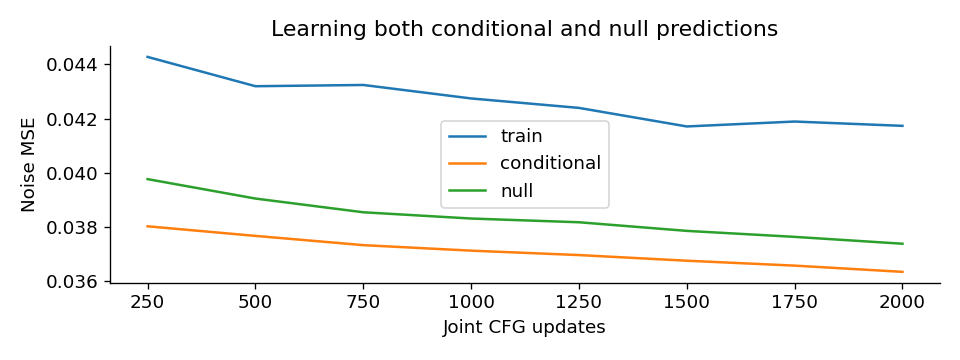

In [ ]:
cfg_val_rng = torch.Generator().manual_seed(909)
cfg_val_t = torch.randint(T,(len(validation_images),),generator=cfg_val_rng).to(device)
cfg_val_noise = torch.randn(validation_images.shape,generator=cfg_val_rng).to(device)
cfg_val_y = test_set.targets[:len(validation_images)].to(device)

@torch.no_grad()
def cfg_validation():
    totals = [0.,0.]
    for x,y,t,eps in zip(validation_images.split(64),cfg_val_y.split(64),cfg_val_t.split(64),cfg_val_noise.split(64)):
        noisy = q_sample(x,t,eps)
        for j,labels in enumerate([y,torch.full_like(y,NULL_LABEL)]):
            totals[j] += F.mse_loss(cfg_ema(noisy,t,labels),eps).item()*len(x)
    return [v/len(validation_images) for v in totals]

def save_cfg_checkpoint(step):
    torch.save({"kind":"classifier_free","T":T,"beta":schedule["beta"].cpu(),
                "drop_prob":CFG_DROP_PROB,"model":cfg_model.state_dict(),
                "ema":cfg_ema.state_dict(),"optimizer":cfg_optimizer.state_dict(),
                "steps":step,"history":cfg_history},CFG_CHECKPOINT)

cfg_model.train();running=0.;count=0;dropped=0;seen=0
synchronize();cfg_started=time.perf_counter()
for step in trange(cfg_completed,CFG_STEPS,desc="Joint CFG training"):
    indices=torch.randint(len(train_images),(CFG_BATCH_SIZE,))
    clean=train_images[indices].float().to(device)/127.5-1
    labels=train_set.targets[indices].to(device)
    used_labels,mask=drop_labels(labels,CFG_DROP_PROB)
    t=torch.randint(T,(len(clean),),device=device);eps=torch.randn_like(clean)
    loss=F.mse_loss(cfg_model(q_sample(clean,t,eps),t,used_labels),eps)
    cfg_optimizer.zero_grad(set_to_none=True);loss.backward()
    nn.utils.clip_grad_norm_(cfg_model.parameters(),1.);cfg_optimizer.step()
    with torch.no_grad():
        decay=min(.995,(1+step)/(10+step))
        for avg,current in zip(cfg_ema.parameters(),cfg_model.parameters()):avg.lerp_(current,1-decay)
    running+=loss.item();count+=1;dropped+=mask.sum().item();seen+=len(clean)
    if (step+1)%250==0 or step+1==CFG_STEPS:
        val_cond,val_null=cfg_validation();synchronize()
        cfg_history.append({"step":step+1,"train":running/count,"conditional":val_cond,"null":val_null})
        print(f"Update {step+1}: train={running/count:.4f}; conditional={val_cond:.4f}; "
              f"null={val_null:.4f}; label dropout={dropped/seen:.1%}")
        running=0.;count=0;save_cfg_checkpoint(step+1)
cfg_completed=max(cfg_completed,CFG_STEPS);cfg_ema.eval()
print(f"Saved {CFG_CHECKPOINT.name}")
fig,ax=plt.subplots(figsize=(8,3))
cfg_losses=pd.DataFrame(cfg_history)
for key in ["train","conditional","null"]:ax.plot(cfg_losses.step,cfg_losses[key],label=key)
ax.set(xlabel="Joint CFG updates",ylabel="Noise MSE",title="Learning both conditional and null predictions")
ax.legend();plt.tight_layout();plt.show()

### Sampling with a guidance scale

Wrap the trained noise predictor; reuse the existing DDIM or DDPM transition formulas. For a general scale we evaluate both branches at each step. At scale 0 or 1 we can skip the unused branch. Thus 50 sampler steps usually cost 100 noise-predictor evaluations with CFG, versus 50 for either endpoint. Clean-image clipping remains the same at every scale; high guidance can interact with clipping.

**Checks:** scale 0 equals the null prediction; scale 1 equals the conditional prediction; scale 0 ignores the requested class; changing the extra-noise seed leaves deterministic DDIM unchanged.

In [ ]:
class GuidedNoise(nn.Module):
    def __init__(self,network,scale):
        super().__init__()
        if not math.isfinite(scale) or scale<0:raise ValueError("Guidance scale must be finite and nonnegative")
        self.network=network;self.scale=float(scale)
    def forward(self,x,t,y):
        if self.scale==1.:return self.network(x,t,y)
        null=self.network(x,t,torch.full_like(y,NULL_LABEL))
        if self.scale==0.:return null
        conditional=self.network(x,t,y)
        return null+self.scale*(conditional-null)

cfg_check_rng=torch.Generator().manual_seed(70)
cfg_check_x=torch.randn((2,1,28,28),generator=cfg_check_rng).to(device)
cfg_check_t=torch.tensor([20,130],device=device);cfg_check_y=torch.tensor([3,8],device=device)
with torch.no_grad():
    uncond=cfg_ema(cfg_check_x,cfg_check_t,torch.full_like(cfg_check_y,NULL_LABEL))
    cond=cfg_ema(cfg_check_x,cfg_check_t,cfg_check_y)
    assert torch.equal(GuidedNoise(cfg_ema,0)(cfg_check_x,cfg_check_t,cfg_check_y),uncond)
    assert torch.equal(GuidedNoise(cfg_ema,1)(cfg_check_x,cfg_check_t,cfg_check_y),cond)
    assert torch.allclose(GuidedNoise(cfg_ema,2)(cfg_check_x,cfg_check_t,cfg_check_y),2*cond-uncond,atol=1e-5)
    assert torch.equal(GuidedNoise(cfg_ema,0)(cfg_check_x,cfg_check_t,cfg_check_y.flip(0)),uncond)
# Both the null embedding and digit embeddings must receive training gradients.
cfg_optimizer.zero_grad(set_to_none=True)
cfg_model(cfg_check_x,cfg_check_t,torch.tensor([NULL_LABEL,3],device=device)).square().mean().backward()
assert cfg_model.class_embedding.weight.grad[NULL_LABEL].abs().sum()>0
assert cfg_model.class_embedding.weight.grad[3].abs().sum()>0
cfg_optimizer.zero_grad(set_to_none=True)
a,_,_,_=sample(GuidedNoise(cfg_ema,2),cfg_check_x,"ddim",20,seed=1,class_labels=cfg_check_y)
b,_,_,_=sample(GuidedNoise(cfg_ema,2),cfg_check_x,"ddim",20,seed=2,class_labels=cfg_check_y)
assert torch.allclose(a,b,atol=1e-6)
print("Passed: guidance endpoints, scale-2 formula, class independence at scale 0, both embedding gradients, DDIM repeatability.")

Passed: guidance endpoints, scale-2 formula, class independence at scale 0, both embedding gradients, DDIM repeatability.


### Sweep: same weights, labels, noise and 50 DDIM steps

Generate 64 images per requested digit at scales **0, 1, 2, 4, 8**. Every scale uses exactly the same 640 starting noise images. The images shown below are fixed positions from this batch, without selecting successful examples.

First inspect all ten digits; then inspect eight noise seeds for one digit. Follow a column as guidance increases: check class agreement, stroke shape and variation in handwriting. A larger scale is not a promise of better visual quality.

Scale 0: 640 generated images
Scale 1: 640 generated images
Scale 2: 640 generated images
Scale 4: 640 generated images
Scale 8: 640 generated images


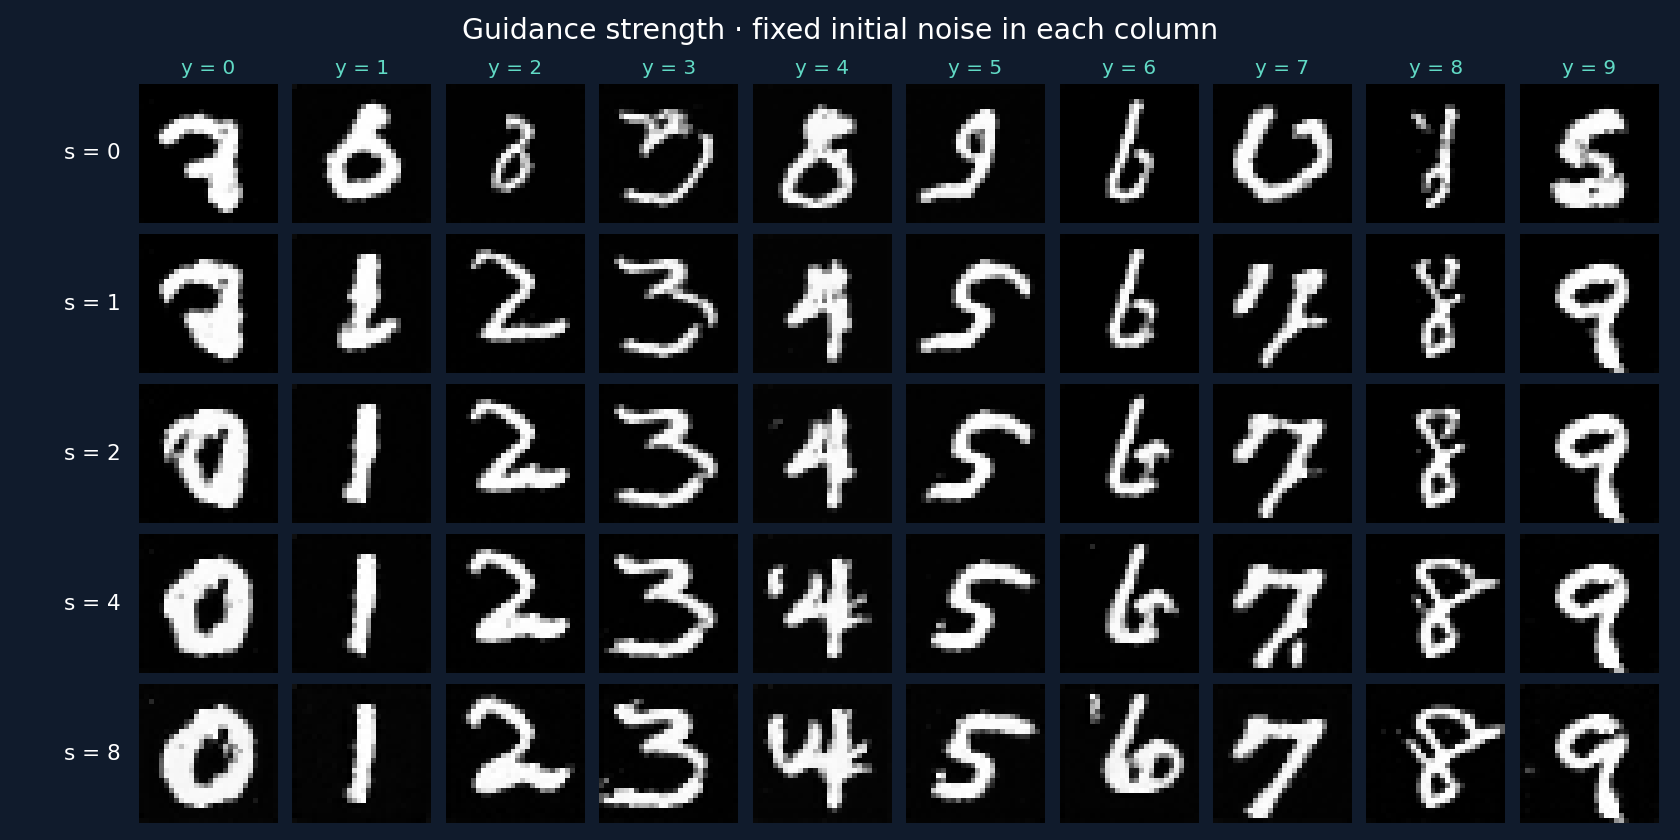

In [ ]:
CFG_SCALES=[0.,1.,2.,4.,8.]
CFG_SAMPLING_STEPS=50
CFG_PER_DIGIT=64
CFG_SAMPLE_BATCH=64
cfg_sample_rng=torch.Generator().manual_seed(20261107)
cfg_requested=torch.arange(10).repeat_interleave(CFG_PER_DIGIT)
cfg_start=torch.randn((len(cfg_requested),1,28,28),generator=cfg_sample_rng)
cfg_samples={}
for scale in CFG_SCALES:
    chunks=[]
    for noise,labels in zip(cfg_start.split(CFG_SAMPLE_BATCH),cfg_requested.split(CFG_SAMPLE_BATCH)):
        images,_,_,_=sample(GuidedNoise(cfg_ema,scale),noise.to(device),"ddim",CFG_SAMPLING_STEPS,
                           class_labels=labels.to(device))
        chunks.append(images)
    cfg_samples[scale]=torch.cat(chunks)
    print(f"Scale {scale:g}: {len(cfg_samples[scale])} generated images")

fig,axes=plt.subplots(len(CFG_SCALES),10,figsize=(14,7),facecolor="#101b2c")
for row,scale in enumerate(CFG_SCALES):
    for digit,ax in enumerate(axes[row]):
        ax.imshow(cfg_samples[scale][digit*CFG_PER_DIGIT,0],cmap="gray",vmin=-1,vmax=1);ax.axis("off")
        if row==0:ax.set_title(f"y = {digit}",color="#61dac5",fontsize=12)
    axes[row,0].text(-.13,.5,f"s = {scale:g}",transform=axes[row,0].transAxes,ha="right",va="center",color="white",fontsize=13)
fig.suptitle("Guidance strength · fixed initial noise in each column",color="white",fontsize=17)
fig.subplots_adjust(left=.08,right=.99,top=.90,bottom=.02,hspace=.08,wspace=.04);plt.show()

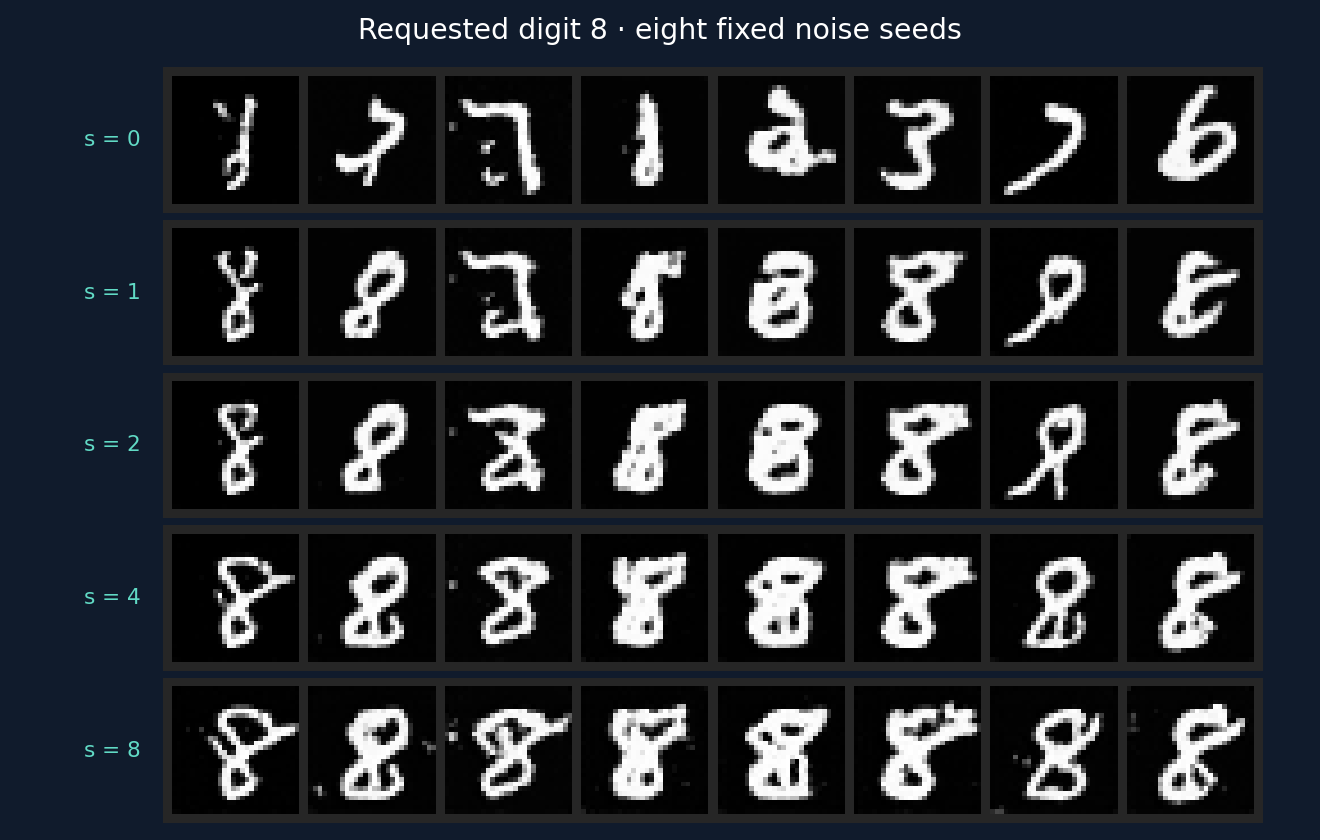

In [ ]:
CFG_DIGIT=8  # Change the requested digit; no retraining or resampling needed.
assert isinstance(CFG_DIGIT,int) and 0<=CFG_DIGIT<=9
fig,axes=plt.subplots(len(CFG_SCALES),1,figsize=(11,7),facecolor="#101b2c")
for ax,scale in zip(axes,CFG_SCALES):
    start=CFG_DIGIT*CFG_PER_DIGIT
    show_grid(cfg_samples[scale][start:start+8],"",8,ax)
    ax.text(-.02,.5,f"s = {scale:g}",transform=ax.transAxes,ha="right",va="center",color="#61dac5",fontsize=13)
fig.suptitle(f"Requested digit {CFG_DIGIT} · eight fixed noise seeds",color="white",fontsize=17)
fig.subplots_adjust(left=.09,right=.99,top=.92,bottom=.02,hspace=.05);plt.show()

### Measure class agreement and within-class diversity

The samples above were generated **without a classifier**. We now train a separate small MNIST classifier on real training images only, freeze it, and report its accuracy on all 10,000 held-out test images. It is used only for evaluation; it never enters the sampler or the diffusion loss.

- **Requested-label agreement:** fraction of generated images classified as the requested digit. This is a proxy for control, not a complete image-quality score. A confident classifier can still accept a distorted image.
- **Within-request diversity:** mean pairwise distance between unit-normalized penultimate classifier features, computed within each requested class, then averaged over the ten classes.
- **Correct-only diversity:** the same distance restricted to images classified as requested. Also report the smallest retained count per class; this subset changes with guidance, so inspect both diversity measures and the grids.

The real-data reference uses 64 held-out MNIST images per digit, selected with a fixed seed. Feature distances are a teaching diagnostic, not FID or proof of mode coverage. Compare style diversity primarily for $s\geq1$: at $s=0$, different actual digit classes inflate within-request distances.

If any class retains fewer than two correctly classified images, the aggregate correct-only diversity is left undefined (NaN), rather than silently averaging over fewer classes. Check `classes_with_2_correct` and the per-class counts.

In [ ]:
class DigitEvaluator(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv=nn.Sequential(nn.Conv2d(1,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
                                nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.MaxPool2d(2))
        self.features=nn.Sequential(nn.Flatten(),nn.Linear(64*7*7,128),nn.ReLU())
        self.head=nn.Linear(128,10)
    def forward(self,x,return_features=False):
        h=self.features(self.conv(x))
        return (self.head(h),h) if return_features else self.head(h)

EVALUATOR_EPOCHS=2
torch.manual_seed(31415)
evaluator=DigitEvaluator().to(device)
evaluator_optimizer=torch.optim.Adam(evaluator.parameters(),lr=1e-3)
for epoch in range(EVALUATOR_EPOCHS):
    evaluator.train();order=torch.randperm(len(train_images));total_loss=0.
    for indices in order.split(128):
        x=train_images[indices].float().to(device)/127.5-1;y=train_set.targets[indices].to(device)
        loss=F.cross_entropy(evaluator(x),y)
        evaluator_optimizer.zero_grad(set_to_none=True);loss.backward();evaluator_optimizer.step()
        total_loss+=loss.item()*len(indices)
    print(f"Evaluator epoch {epoch+1}: train CE={total_loss/len(train_images):.4f}")
evaluator.eval().requires_grad_(False)

@torch.inference_mode()
def evaluate_images(images):
    predictions=[];features=[]
    for x in images.split(256):
        logits,h=evaluator(x.to(device),return_features=True)
        predictions.append(logits.argmax(1).cpu());features.append(F.normalize(h,dim=1).cpu())
    return torch.cat(predictions),torch.cat(features)

real_test=test_set.data[:,None].float()/127.5-1
real_predictions,real_features=evaluate_images(real_test)
evaluator_accuracy=(real_predictions==test_set.targets).float().mean().item()
print(f"Held-out classifier accuracy: {evaluator_accuracy:.2%} on {len(real_test):,} real images")
if evaluator_accuracy<.98:print("Evaluator accuracy is below 98%; interpret agreement cautiously or train longer.")
# Save locally to reproduce evaluation; this file is not needed by the sampler.
torch.save(evaluator.state_dict(),"mnist_cfg_evaluator.pt")

Evaluator epoch 1: train CE=0.2106
Evaluator epoch 2: train CE=0.0513
Held-out classifier accuracy: 98.60% on 10,000 real images


 scale  agreement  agreement_low  agreement_high  diversity_all  diversity_correct  min_correct_per_digit  classes_with_2_correct
   0.0     0.1031         0.0819          0.1291         0.8401                NaN                      1                       9
   1.0     0.8562         0.8269          0.8813         0.5650             0.5105                     47                      10
   2.0     0.9859         0.9735          0.9926         0.4062             0.3998                     61                      10
   4.0     1.0000         0.9940          1.0000         0.3355             0.3355                     64                      10
   8.0     1.0000         0.9940          1.0000         0.3035             0.3035                     64                      10
Real held-out within-class feature diversity: 0.4643
Requested-label agreement by digit:
scale   0.0   1.0    2.0    4.0    8.0
digit                                 
0      10.9  85.9  100.0  100.0  100.0
1       1.6  8

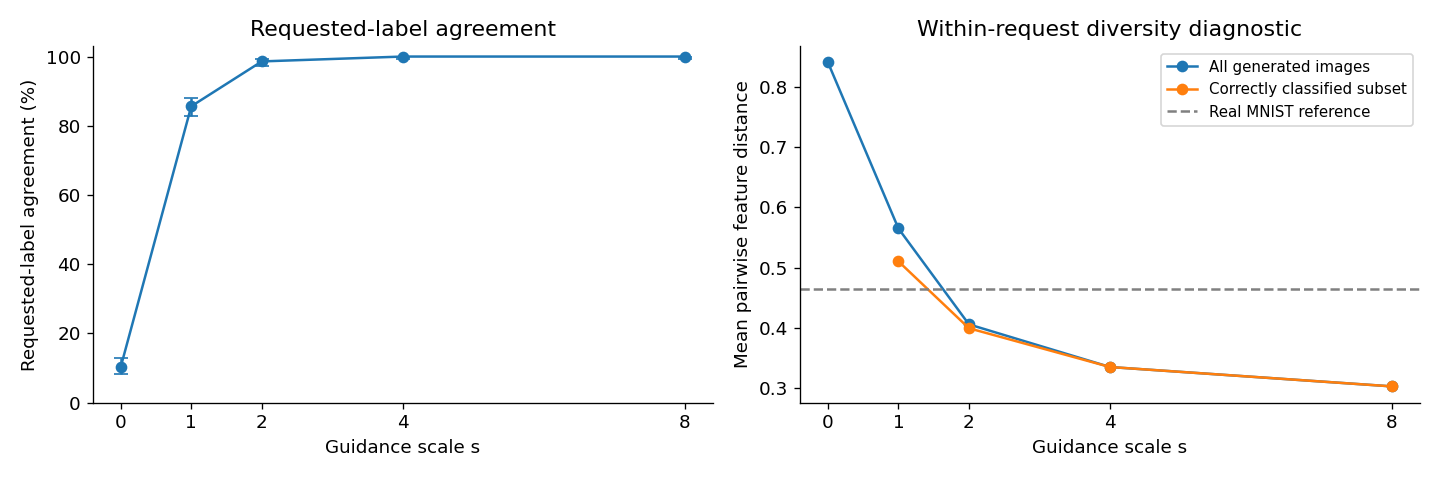

In [ ]:
def pairwise_feature_distance(features):
    if len(features)<2:return float("nan")
    return torch.pdist(features,p=2).mean().item()

def wilson_interval(successes,total,z=1.96):
    fraction=successes/total;denom=1+z*z/total
    center=(fraction+z*z/(2*total))/denom
    half=z*math.sqrt(fraction*(1-fraction)/total+z*z/(4*total*total))/denom
    return center-half,center+half

reference_rng=torch.Generator().manual_seed(1618)
reference_diversity=[]
for digit in range(10):
    candidates=(test_set.targets==digit).nonzero().flatten()
    selected=candidates[torch.randperm(len(candidates),generator=reference_rng)[:CFG_PER_DIGIT]]
    reference_diversity.append(pairwise_feature_distance(real_features[selected]))
real_diversity=float(np.mean(reference_diversity))
cfg_metric_rows=[];cfg_class_rows=[]
for scale in CFG_SCALES:
    predicted,features=evaluate_images(cfg_samples[scale]);correct=predicted==cfg_requested
    all_diversity=[];correct_diversity=[];counts=[]
    for digit in range(10):
        group=cfg_requested==digit;kept=group & correct
        d_all=pairwise_feature_distance(features[group]);d_correct=pairwise_feature_distance(features[kept])
        all_diversity.append(d_all);correct_diversity.append(d_correct);counts.append(int(kept.sum()))
        cfg_class_rows.append({"scale":scale,"digit":digit,"agreement":correct[group].float().mean().item(),
                               "diversity_all":d_all,"diversity_correct":d_correct,"correct_count":int(kept.sum())})
    low,high=wilson_interval(int(correct.sum()),len(correct))
    cfg_metric_rows.append({"scale":scale,"agreement":correct.float().mean().item(),"agreement_low":low,
                           "agreement_high":high,"diversity_all":np.mean(all_diversity),
                           "diversity_correct":(np.mean(correct_diversity) if all(c>=2 for c in counts) else float("nan")),"min_correct_per_digit":min(counts),
                           "classes_with_2_correct":sum(c>=2 for c in counts)})
cfg_metrics=pd.DataFrame(cfg_metric_rows);cfg_per_class=pd.DataFrame(cfg_class_rows)
print(cfg_metrics.round(4).to_string(index=False))
print(f"Real held-out within-class feature diversity: {real_diversity:.4f}")
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].errorbar(cfg_metrics.scale,cfg_metrics.agreement*100,
    yerr=np.vstack([(cfg_metrics.agreement-cfg_metrics.agreement_low)*100,
                    (cfg_metrics.agreement_high-cfg_metrics.agreement)*100]),fmt="o-",capsize=4)
axes[0].set(xlabel="Guidance scale s",ylabel="Requested-label agreement (%)",ylim=(0,103),
            title="Requested-label agreement")
axes[1].plot(cfg_metrics.scale,cfg_metrics.diversity_all,"o-",label="All generated images")
axes[1].plot(cfg_metrics.scale,cfg_metrics.diversity_correct,"o-",label="Correctly classified subset")
axes[1].axhline(real_diversity,color="gray",ls="--",label="Real MNIST reference")
axes[1].set(xlabel="Guidance scale s",ylabel="Mean pairwise feature distance",title="Within-request diversity diagnostic")
for ax in axes:ax.set_xticks(CFG_SCALES)
axes[1].legend(fontsize=9);plt.tight_layout();plt.show()
# Per-class results make failures hidden by the overall average visible.
print("Requested-label agreement by digit:")
print((100*cfg_per_class.pivot(index="digit",columns="scale",values="agreement")).round(1).to_string())

### What the saved run shows

The evaluator reached **98.60% accuracy on 10,000 real test digits**. On the 640 generated images per scale:

| Guidance scale | Requested-label agreement | Correct-only feature diversity |
|---:|---:|---:|
| 1 | 85.62% | 0.5105 |
| 2 | 98.59% | 0.3998 |
| 4 | 100.00% | 0.3355 |
| 8 | 100.00% | 0.3035 |

Scale 2 gives a large improvement in class control here, with less variation by this feature diagnostic. At 4 and 8, all 640 outputs are classified as requested; that does **not** mean every image is visually perfect. The fixed-seed grids show coarse or distorted strokes at high guidance, particularly among the 8s. Scale 8 adds no measured agreement over 4 in this run while reducing the diversity diagnostic further. Real held-out within-class diversity is 0.4643; it is a reference, not a target to maximize blindly.

Scale 0 agrees with the arbitrary requested labels on 10.31% of samples. One digit has only one correctly classified example, so aggregate correct-only diversity is undefined there. All outcomes above belong to this checkpoint, seed set and evaluator; rerunning the default longer training can change them.

### Read the experiment, not just the curve

The error bars are 95% Wilson intervals for the classifier-agreement proportions at each scale. Scales reuse the same starting samples, so their results are paired; overlapping or non-overlapping bars are not a formal test of their difference. One model checkpoint, one evaluator and 64 samples per class do not establish a universal optimum.

**Discuss:** does agreement improve from $s=1$ to $s=2$ or $4$? Which handwriting variations disappear? At $s=8$, are strokes distorted, or do the metrics merely reward more stereotypical digits? If diversity rises together with artifacts, that is not useful diversity. If the curves are non-monotonic, report what this run shows rather than forcing the expected story.

**Try:** change `CFG_DIGIT` to inspect another class; repeat the sweep with a new noise seed; compare 20 and 50 DDIM steps at the same scales. Keep weights and evaluation protocol fixed. Increasing the guidance scale requires no retraining; changing the label-drop probability does require joint training again.

## Save or restore your work
The training cell writes `mnist_ddpm_checkpoint.pt`. To continue in a new Colab runtime, upload this file into the working directory, run setup/data/schedule/model cells, set `RESUME=True`, increase `TRAIN_STEPS`, and run training. Resume restores optimizer and weights but does not reproduce the exact interrupted random stream.

Optional Colab download (run manually):
```python
from google.colab import files
files.download(str(CHECKPOINT))
```

Sources: [DDPM — Ho et al. (2020)](https://arxiv.org/abs/2006.11239), [DDIM — Song et al. (2020)](https://arxiv.org/abs/2010.02502), [Improved DDPM — Nichol & Dhariwal (2021)](https://arxiv.org/abs/2102.09672). Diagrams and grids in this notebook are generated by its own code from MNIST and this model's outputs.

The conditional experiment writes a separate `mnist_conditional_ddpm_checkpoint.pt`. To resume it, run setup/data/schedule/model/sampler definitions, set `CONDITIONAL_RESUME=True`, increase `CONDITIONAL_STEPS`, then run conditional initialization and training. The stored conditional weights replace initialization; unconditional training is unnecessary when restoring this checkpoint. To download in Colab: `files.download(str(CONDITIONAL_CHECKPOINT))` after importing `files` as above.

CFG uses `mnist_cfg_checkpoint.pt`. Set `CFG_RESUME=True` and increase `CFG_STEPS` to continue joint training after running setup/data/schedule and the model definitions (including `ConditionalUNet`); restoring the CFG checkpoint does not require rerunning the earlier training stages. Download with `files.download(str(CFG_CHECKPOINT))`. The separately saved `mnist_cfg_evaluator.pt` is only for evaluation. Resume does not restore the exact RNG stream.